# PSI3442 — P2 — Questão 1: modelo SysML 2.0 (níveis 0, 1 e n)

As células de código abaixo são cópias dos arquivos `*.sysml` desta pasta. Edite os arquivos e rode `python executar_modelo.py --so-gerar` para atualizar o notebook. Execute tudo com *Run → Run All Cells*.

## `00_Comum.sysml`

In [1]:
package Comum {
    doc /* Tipos, sinais, portas e requisitos compartilhados pelos níveis 0, 1 e n.
           PSI3442 — P2 2026 — Questão 1 (voo de familiarização com DJI Mini 4 Pro). */

    private import ScalarValues::*;
    private import ISQ::*;
    private import SI::*;

    // ------------------------------------------------------------------ grandezas físicas e energia
    item def Energia { doc /* Energia elétrica fornecida por bateria. */ }
    item def Empuxo { doc /* Força e torque aplicados ao ar pelas hélices. */ }
    item def SinalVisual { doc /* Indicação luminosa (LEDs de status). */ }
    item def AcaoManual { doc /* Ação física do operador: ligar/desligar, trocar bateria, posicionar. */ }
    item def GrandezaFisica { doc /* Grandeza do ambiente percebida por um sensor. */ }
    item def Distancia :> GrandezaFisica;
    item def Pressao :> GrandezaFisica;
    item def TexturaIluminacao :> GrandezaFisica { doc /* Textura do piso e iluminação: condição para o posicionamento visual. */ }
    item def Imagem :> GrandezaFisica;
    item def SinalGNSS :> GrandezaFisica { doc /* Indisponível em ambiente interno (R07): não utilizado pela missão. */ }

    // ------------------------------------------------------------------ dados
    attribute def ReferencialLocal {
        doc /* Referencial local da missão (P02), dextrogiro:
               origem = ponto de decolagem no piso (A projetado no piso);
               x = horizontal de A para B (direção do nariz da aeronave na decolagem, guinada psi0);
               y = horizontal de A para D (à esquerda do nariz);
               z = vertical para cima, medida do piso ao ponto de referência da aeronave (P01).
               Conversão a partir da telemetria (norte, leste, baixo):
               x =  N cos(psi0) + E sin(psi0);  y = N sin(psi0) - E cos(psi0);  vz = -vBaixo. */
        attribute guinadaDecolagem : Real;
    }

    attribute def Ponto3D {
        doc /* Coordenadas no ReferencialLocal. */
        attribute x : LengthValue;
        attribute y : LengthValue;
        attribute z : LengthValue;
    }

    enum def SentidoPercurso {
        doc /* Com x para B, y para D e z para cima, A-B-C-D é anti-horário visto de cima. */
        enum abcd;   // A -> B -> C -> D -> A
        enum adcb;   // A -> D -> C -> B -> A
    }

    enum def TipoFalha {
        enum perdaEnlace;
        enum telemetriaAtrasada;
        enum bateriaBaixa;
        enum estimativaInvalida;
        enum posicionamentoVisualInativo;
        enum desvioExcessivo;
        enum tempoMissaoExcedido;
        enum comandoRejeitado;
    }

    enum def TipoComando {
        enum decolar;
        enum pousar;
        enum habilitarControleVirtual;
        enum desabilitarControleVirtual;
        enum pararEPairar;
    }

    item def Telemetria {
        doc /* Amostra publicada pelo drone (caixa-preta) e lida via DJI Mobile SDK.
               Velocidades no referencial do solo (norte, leste, baixo); altura relativa ao ponto de decolagem. */
        attribute instante : DurationValue;
        attribute vNorte : SpeedValue;
        attribute vLeste : SpeedValue;
        attribute vBaixo : SpeedValue;
        attribute altitude : LengthValue;
        attribute alturaToF : LengthValue;
        attribute guinada : Real;
        attribute emVoo : Boolean;
        attribute motoresLigados : Boolean;
        attribute modoVoo : String;
        attribute bateriaPercentual : Real;
        attribute conectado : Boolean;
    }

    item def ComandoVelocidade {
        doc /* Comando de controle virtual em velocidade, referencial do solo. */
        attribute vx : SpeedValue;
        attribute vy : SpeedValue;
        attribute vz : SpeedValue;
        attribute taxaGuinada : Real;
    }

    item def ComandoDiscreto {
        attribute tipo : TipoComando;
    }

    item def ConfiguracaoMissao {
        doc /* Conteúdo do arquivo de configuração (JSON). */
        attribute vertices : Ponto3D[4];
        attribute sentido : SentidoPercurso;
        attribute alturaAlvo : LengthValue;
        attribute aresta : LengthValue;
        attribute tempoPermanencia : DurationValue;
        attribute tolHorizontal : LengthValue;
        attribute tolVertical : LengthValue;
        attribute vPairadoMax : SpeedValue;
        attribute vToqueMax : SpeedValue;
        attribute vDeslocamentoMax : SpeedValue;
        attribute bateriaMinimaPercentual : Real;
        attribute tempoMaxMissao : DurationValue;
        attribute tempoEstabilizacao : DurationValue;
    }

    item def ComandoOperador {
        doc /* O operador apenas inicia, interrompe ou aborta: não pilota continuamente (R03). */
    }
    item def DadosPainel { doc /* Estado da missão, vértice atual, cronômetro, telemetria e falhas. */ }
    item def RegistroLog { doc /* Linha de log: instante, estado, estimativa, comando, evento. */ }
    item def PacoteDados { doc /* Comandos, telemetria e vídeo trafegando entre aplicação, controle remoto e aeronave. */ }

    // ------------------------------------------------------------------ sinais da máquina de estados
    attribute def IniciarMissao { doc /* Operador pressiona Iniciar no painel. */ }
    attribute def InterromperMissao { doc /* Operador pressiona Interromper no painel. */ }
    attribute def PreparacaoConcluida {
        doc /* Aeronave conectada, bateria >= mínimo, posicionamento visual ativo, ação de perda de sinal = pousar
               confirmada por leitura, controle virtual habilitado e guinada psi0 registrada. */
    }
    attribute def DecolagemConcluida { doc /* emVoo = true e |vz| <= vPairadoMax após o comando de decolagem automática. */ }
    attribute def AlturaAtingida { doc /* |z - alturaAlvo| <= tolVertical e |v| <= vPairadoMax. */ }
    attribute def VerticeAtingido { doc /* Veredito "dentro" no setpoint atual (erro horizontal, vertical e velocidade). */ }
    attribute def ToleranciaExcedida { doc /* Veredito passa de "dentro" para "fora" durante a permanência: zera o cronômetro (P05). */ }
    attribute def PermanenciaConcluida { doc /* Cronômetro atinge tempoPermanencia contínuo em tempo real. */ }
    attribute def Estabilizado { doc /* Veredito "dentro" em A (retorno) mantido por tempoEstabilizacao. */ }
    attribute def PousoConfirmado { doc /* Telemetria: emVoo = false e motoresLigados = false. */ }
    attribute def FalhaDetectada {
        doc /* Emitido pelo monitor de falhas ou pelo adaptador (comando rejeitado pelo SDK). */
        attribute tipo : TipoFalha;
    }

    // ------------------------------------------------------------------ portas
    port def PortaEnergia { in item energia : Energia; }
    port def PortaAcaoManual { in item acao : AcaoManual; }
    port def PortaSensorial { in item grandeza : GrandezaFisica; }
    port def PortaEmpuxo { out item empuxo : Empuxo; }
    port def PortaSinalVisual { out item sinal : SinalVisual; }
    port def PortaRF { inout item pacote : PacoteDados; }
    port def PortaUSB { inout item pacote : PacoteDados; }
    port def PortaArmazenamento { inout item midia : PacoteDados; }
    port def PortaConfiguracao { in item config : ConfiguracaoMissao; }
    port def PortaLogs { out item registro : RegistroLog; }
    port def PortaPainel { out item dados : DadosPainel; }
    port def PortaOperador { in item comando : ComandoOperador; }
    port def PortaTelemetria { out item telemetria : Telemetria; }
    port def PortaComandos {
        in item velocidade : ComandoVelocidade;
        in item discreto : ComandoDiscreto;
    }

    // ------------------------------------------------------------------ requisitos da Questão 1
    package RequisitosQ1 {
        requirement def <P01> Decolagem {
            doc /* Decolar verticalmente a partir do ponto inicial e atingir 1,80 m de altura em relação ao piso.
                   Ponto de referência geométrico declarado: plano inferior do corpo da aeronave (sensores inferiores),
                   mantido em todas as medições. */
            subject sujeito;
            attribute alturaAlvo : LengthValue = 1.80 [m];
            attribute alturaMedida : LengthValue;
            attribute tolVertical : LengthValue;
            require constraint { alturaMedida - alturaAlvo <= tolVertical and alturaAlvo - alturaMedida <= tolVertical }
        }

        requirement def <P02> QuadradoHorizontal {
            doc /* Percorrer um quadrado horizontal de aresta 1,50 m a 1,80 m de altura:
                   A=(0;0;1,80) B=(1,50;0;1,80) C=(1,50;1,50;1,80) D=(0;1,50;1,80), A acima do ponto de decolagem.
                   Sentido escolhido pela equipe. */
            subject sujeito;
            attribute aresta : LengthValue = 1.50 [m];
            attribute alturaAlvo : LengthValue = 1.80 [m];
        }

        requirement def <P03> PermanenciaNosVertices {
            doc /* Pairar pelo menos 60 s contínuos em A, B, C e D, nesta ordem (ou A, D, C, B);
                   sem segunda espera no retorno a A. */
            subject sujeito;
            attribute tempoPermanencia : DurationValue = 60 [s];
            attribute tempoMedido : DurationValue;
            require constraint { tempoMedido >= tempoPermanencia }
        }

        requirement def <P04> PousoSuave {
            doc /* Retornar ao ponto inicial e pousar com redução controlada da velocidade vertical;
                   encerrar após confirmar o pouso por telemetria. */
            subject sujeito;
            attribute vToqueMax : SpeedValue;
            attribute vToqueMedida : SpeedValue;
            require constraint { vToqueMedida <= vToqueMax }
        }

        requirement def <P05> ToleranciasDeclaradas {
            doc /* Tolerâncias de posição e altura, limite de velocidade de voo pairado e de velocidade vertical no toque,
                   definidos antes dos testes e aprovados na entrega intermediária. A contagem de permanência reinicia
                   se as tolerâncias forem excedidas. Não podem ser ampliados retrospectivamente. */
            subject sujeito;
        }

        requirement def <P06> EvidenciaEModelo {
            doc /* Modelo SysML 2.0 (níveis 0, 1 e n), implementação executável, configuração da trajetória, logs e
                   evidências em voo real; estados de decolagem, deslocamento, permanência, retorno, pouso e falha;
                   60 s medidos em tempo real. */
            subject sujeito;
        }

        requirement def <R07> FalhasEmAmbienteInterno {
            doc /* Tratar perda de comunicação, bateria insuficiente, estimativa inválida e tempo excedido com estados
                   de término seguro adequados a uma sala. Retorno automático por GNSS não é solução válida. */
            subject sujeito;
        }
    }
}


Package Comum (ad9f47f2-bd6f-4ffa-bc46-c908ebaca802)


## `01_Nivel0.sysml`

In [2]:
package Nivel0 {
    doc /* Nível 0 — sistema de interesse, atores externos, cenário de operação, fronteiras, entradas, saídas e
           fluxos de informação e energia. Corresponde ao diagrama diagramas/nivel_0.png.

           Diferenças em relação ao modelo da primeira prova (outro drone), justificadas pelo Mini 4 Pro e pela sala:
           - GPS mantido apenas como entrada indisponível: em ambiente interno não há GNSS confiável (R07);
             a posição vem do posicionamento visual (câmeras inferiores) e do sensor ToF.
           - Entrada "textura do piso / iluminação" acrescentada: condição de funcionamento do posicionamento visual.
           - Botão Reset removido: não existe no Mini 4 Pro.
           - Cartão de memória passa a ser bidirecional (armazenamento) e ligado à computação embarcada.
           - Estação de solo decomposta em controle remoto e celular Android com a aplicação de missão: o Mobile SDK
             roda no celular; nenhum código da missão é instalado no controlador de voo.
           - Entradas/saídas acrescentadas: arquivo de configuração, logs exportáveis, comandos do operador limitados
             a iniciar/interromper, energia da estação de solo. */

    private import Comum::*;
    private import Comum::RequisitosQ1::*;

    // ------------------------------------------------------------------ elementos externos
    part def Operador {
        doc /* Ator externo: inicia e interrompe a missão; não pilota continuamente. */
        port comando : ~PortaOperador;
        port painel : ~PortaPainel;
        port acaoManual : ~PortaAcaoManual;
        port leds : ~PortaSinalVisual;
    }

    part def AmbienteFisico {
        doc /* Sala de aula: piso (textura), paredes, teto, mobiliário, iluminação e ar. */
        port distancia : ~PortaSensorial;
        port pressao : ~PortaSensorial;
        port texturaIluminacao : ~PortaSensorial;
        port imagem : ~PortaSensorial;
        port empuxo : ~PortaEmpuxo;
    }

    part def FonteEnergia {
        doc /* Baterias carregadas: aeronave, controle remoto e celular. */
        port aeronave : ~PortaEnergia;
        port estacao : ~PortaEnergia;
    }

    part def ArquivoConfiguracao {
        doc /* Arquivo JSON com vértices, tolerâncias e tempos da missão (R01, P05). */
        port saida : ~PortaConfiguracao;
    }

    part def RepositorioLogs {
        doc /* Destino dos logs exportáveis (CSV) usados como evidência (P06). */
        port entrada : ~PortaLogs;
    }

    part def SatelitesGNSS {
        doc /* Indisponíveis em ambiente interno: representados apenas para registrar que não são usados (R07). */
        port sinal : ~PortaSensorial;
    }

    part def Simulador {
        doc /* Opcional — ambiente de teste. Substitui controle remoto + aeronave e oferece à aplicação a mesma
               interface do adaptador DJI. Resultados identificados separadamente dos de voo real, com a escala de
               tempo usada (P06). Uso ainda a decidir pela equipe. */
        port interfaceAdaptador : PortaUSB;
    }

    // ------------------------------------------------------------------ sistema de interesse
    part def Drone {
        doc /* DJI Mini 4 Pro — produto comercial tratado como caixa-preta. */
        port bateria : PortaEnergia;
        port botaoOnOff : PortaAcaoManual;
        port distancia : PortaSensorial;
        port pressao : PortaSensorial;
        port texturaIluminacao : PortaSensorial;
        port imagem : PortaSensorial;
        port gps : PortaSensorial { doc /* Indisponível indoor. */ }
        port conexaoUSB : PortaUSB;
        port cartaoMemoria : PortaArmazenamento;
        port empuxo : PortaEmpuxo;
        port ledReady : PortaSinalVisual;
        port rf : PortaRF;
    }

    part def ControleRemoto {
        doc /* Controle remoto compatível com o Mobile SDK (RC-N2 — verificar). */
        port rf : PortaRF;
        port usb : PortaUSB;
        port bateria : PortaEnergia;
    }

    part def AplicacaoMissao {
        doc /* Software da missão (Kotlin, DJI Mobile SDK v5). Comum às Questões 1 e 2: comando, supervisão e registro. */
        port sdk : PortaUSB;
        port config : PortaConfiguracao;
        port logs : PortaLogs;
        port display : PortaPainel;
        port comandosOperador : PortaOperador;
    }

    part def CelularAndroid {
        doc /* Hardware que executa a aplicação de missão. */
        port usb : PortaUSB;
        port config : PortaConfiguracao;
        port logs : PortaLogs;
        port display : PortaPainel;
        port comandosOperador : PortaOperador;
        port bateria : PortaEnergia;

        part app : AplicacaoMissao;

        connect usb to app.sdk;
        connect config to app.config;
        connect app.logs to logs;
        connect app.display to display;
        connect comandosOperador to app.comandosOperador;
    }

    part def EstacaoSolo {
        port rf : PortaRF;
        port bateria : PortaEnergia;
        port config : PortaConfiguracao;
        port logs : PortaLogs;
        port display : PortaPainel;
        port comandosOperador : PortaOperador;

        part controleRemoto : ControleRemoto;
        part celular : CelularAndroid;

        connect controleRemoto.usb to celular.usb;
        connect rf to controleRemoto.rf;
        connect bateria to controleRemoto.bateria;
        connect bateria to celular.bateria;
        connect config to celular.config;
        connect celular.logs to logs;
        connect celular.display to display;
        connect comandosOperador to celular.comandosOperador;
    }

    part def SistemaVooAutonomo {
        doc /* Função global: executar autonomamente decolagem, quadrado de 1,50 m a 1,80 m, permanências de 60 s
               nos quatro vértices, retorno e pouso suave, respeitando as tolerâncias declaradas e registrando evidências. */
        part drone : Drone;
        part estacao : EstacaoSolo;
        flow of PacoteDados from estacao.rf.pacote to drone.rf.pacote;
        flow of PacoteDados from drone.rf.pacote to estacao.rf.pacote;
    }

    part def ContextoOperacional {
        part operador : Operador;
        part ambiente : AmbienteFisico;
        part energia : FonteEnergia;
        part arquivoConfig : ArquivoConfiguracao;
        part repositorioLogs : RepositorioLogs;
        part gnss : SatelitesGNSS;
        part sistema : SistemaVooAutonomo;

        // informação
        flow of ComandoOperador from operador.comando.comando to sistema.estacao.comandosOperador.comando;
        flow of DadosPainel from sistema.estacao.display.dados to operador.painel.dados;
        flow of ConfiguracaoMissao from arquivoConfig.saida.config to sistema.estacao.config.config;
        flow of RegistroLog from sistema.estacao.logs.registro to repositorioLogs.entrada.registro;
        flow of SinalVisual from sistema.drone.ledReady.sinal to operador.leds.sinal;
        flow of AcaoManual from operador.acaoManual.acao to sistema.drone.botaoOnOff.acao;

        // grandezas físicas sensoriadas
        flow of Distancia from ambiente.distancia.grandeza to sistema.drone.distancia.grandeza;
        flow of Pressao from ambiente.pressao.grandeza to sistema.drone.pressao.grandeza;
        flow of TexturaIluminacao from ambiente.texturaIluminacao.grandeza to sistema.drone.texturaIluminacao.grandeza;
        flow of Imagem from ambiente.imagem.grandeza to sistema.drone.imagem.grandeza;
        flow of SinalGNSS from gnss.sinal.grandeza to sistema.drone.gps.grandeza;

        // energia e força
        flow of Energia from energia.aeronave.energia to sistema.drone.bateria.energia;
        flow of Energia from energia.estacao.energia to sistema.estacao.bateria.energia;
        flow of Empuxo from sistema.drone.empuxo.empuxo to ambiente.empuxo.empuxo;
    }

    part contexto : ContextoOperacional;

    // ------------------------------------------------------------------ cenário de operação
    use case def CenarioOperacaoQ1 {
        doc /* Cenário de operação do voo de familiarização na sala de aula. */
        subject sistema : SistemaVooAutonomo;
        actor operador : Operador;
        objective { doc /* Demonstrar P01 a P06 em voo real, com o operador apenas iniciando ou interrompendo. */ }

        action prepararAmbiente {
            doc /* Marcar A, B, C e D no piso; garantir piso texturizado e iluminação; volume livre em torno do
                   quadrado com margem de segurança (hipótese: 2,5 m x 2,5 m x 2,5 m). */
        }
        action posicionarAeronave { doc /* Aeronave sobre a marca de A, nariz apontado para B (define psi0). */ }
        action ligarEquipamentos { doc /* Ligar aeronave, controle remoto e celular; conectar USB; abrir a aplicação. */ }
        action carregarConfiguracao { doc /* Selecionar o JSON aprovado; o painel exibe tolerâncias e sentido. */ }
        action iniciarMissao { doc /* Operador pressiona Iniciar; a partir daqui não pilota. */ }
        action executarMissao {
            doc /* Decolagem, quadrado com quatro permanências de 60 s, retorno e pouso. O operador pode Interromper
                   a qualquer momento (pouso no local). */
        }
        action exportarEvidencias { doc /* Exportar o CSV da missão e o vídeo da demonstração. */ }

        first start then prepararAmbiente;
        first prepararAmbiente then posicionarAeronave;
        first posicionarAeronave then ligarEquipamentos;
        first ligarEquipamentos then carregarConfiguracao;
        first carregarConfiguracao then iniciarMissao;
        first iniciarMissao then executarMissao;
        first executarMissao then exportarEvidencias;
        first exportarEvidencias then done;
    }

    // ------------------------------------------------------------------ requisitos alocados ao sistema
    requirement p01 : Decolagem;
    requirement p02 : QuadradoHorizontal;
    requirement p03 : PermanenciaNosVertices;
    requirement p04 : PousoSuave;
    requirement p05 : ToleranciasDeclaradas;
    requirement p06 : EvidenciaEModelo;
    requirement r07 : FalhasEmAmbienteInterno;

    satisfy p01 by contexto.sistema;
    satisfy p02 by contexto.sistema;
    satisfy p03 by contexto.sistema;
    satisfy p04 by contexto.sistema;
    satisfy p05 by contexto.sistema;
    satisfy p06 by contexto.sistema;
    satisfy r07 by contexto.sistema;
}


Package Nivel0 (f52ab1e5-cef0-46ce-88fa-15b545dc0f40)


## `02_Nivel1.sysml`

In [3]:
package Nivel1 {
    doc /* Nível 1 — decomposição dos elementos do nível 0 (diagramas/nivel_1.png) e decomposição funcional da
           função global, com alocação das funções aos blocos. Os blocos internos do drone são caixas-pretas:
           conhecemos suas entradas e saídas, mas não podemos alterá-los. */

    private import ScalarValues::*;
    private import ISQ::*;
    private import Comum::*;
    private import Nivel0::*;

    // ------------------------------------------------------------------ itens e portas internos do drone
    item def InformacaoSensores;
    item def Trigger;
    item def SinalPWM;
    item def FixacaoMecanica;

    port def PortaInfoSensores {
        out item info : InformacaoSensores;
        in item trigger : Trigger;
    }
    port def PortaPWM { in item pwm : SinalPWM; }
    port def PortaFixacao { in item fixacao : FixacaoMecanica; }
    port def PortaPacotes { inout item pacote : PacoteDados; }

    // ------------------------------------------------------------------ dados internos da aplicação
    attribute def EstadoEstimado {
        doc /* Estado da aeronave no referencial local da missão (origem em A projetado no piso). */
        attribute posicao : Ponto3D;
        attribute vx : SpeedValue;
        attribute vy : SpeedValue;
        attribute vz : SpeedValue;
        attribute valido : Boolean;
    }

    attribute def VereditoTolerancia {
        attribute dentroHorizontal : Boolean;
        attribute dentroVertical : Boolean;
        attribute dentroVelocidade : Boolean;
        attribute dentro : Boolean;
    }

    port def PortaEstadoMissao {
        out item estado : DadosPainel;
        in item comando : ComandoOperador;
    }

    // ------------------------------------------------------------------ blocos do drone (caixas-pretas)
    part def Energia {
        doc /* Bateria inteligente de voo: armazena e distribui energia. */
        port bateria : PortaEnergia;
        port alimentacao : ~PortaEnergia;
    }

    part def UnidadeComputacaoEmbarcada {
        doc /* Controlador de voo DJI (firmware fechado): estima a pose, estabiliza e executa comandos do SDK. */
        port alimentacao : PortaEnergia;
        port botaoOnOff : PortaAcaoManual;
        port cartaoMemoria : PortaArmazenamento;
        port ledReady : PortaSinalVisual;
        port sensores : ~PortaInfoSensores;
        port pwm : ~PortaPWM;
        port pacotes : PortaPacotes;
    }

    part def Sensoriamento {
        doc /* IMU, barômetro, ToF inferior, visão inferior e omnidirecional, câmera. */
        port alimentacao : PortaEnergia;
        port distancia : PortaSensorial;
        port pressao : PortaSensorial;
        port texturaIluminacao : PortaSensorial;
        port imagem : PortaSensorial;
        port gps : PortaSensorial;
        port info : PortaInfoSensores;
        port fixacao : PortaFixacao;
    }

    part def Atuadores {
        doc /* Motores, ESCs e hélices; gimbal de 3 eixos da câmera. */
        port alimentacao : PortaEnergia;
        port pwm : PortaPWM;
        port empuxo : PortaEmpuxo;
        port fixacao : PortaFixacao;
    }

    part def Comunicacao {
        doc /* Transceptor DJI O4 e porta USB-C. */
        port alimentacao : PortaEnergia;
        port rf : PortaRF;
        port usb : PortaUSB;
        port pacotes : ~PortaPacotes;
    }

    part def EstruturaFisica {
        doc /* Corpo, braços dobráveis e fixações. */
        port fixacao : ~PortaFixacao;
    }

    part def DroneN1 :> Drone {
        part energia : Energia;
        part uce : UnidadeComputacaoEmbarcada;
        part sensoriamento : Sensoriamento;
        part atuadores : Atuadores;
        part comunicacao : Comunicacao;
        part estrutura : EstruturaFisica;

        // fluxos internos
        connect energia.alimentacao to uce.alimentacao;
        connect energia.alimentacao to sensoriamento.alimentacao;
        connect energia.alimentacao to atuadores.alimentacao;
        connect energia.alimentacao to comunicacao.alimentacao;
        connect sensoriamento.info to uce.sensores;
        connect uce.pwm to atuadores.pwm;
        connect uce.pacotes to comunicacao.pacotes;
        connect estrutura.fixacao to atuadores.fixacao;
        connect estrutura.fixacao to sensoriamento.fixacao;

        // fronteira do nível 0 delegada aos blocos
        connect bateria to energia.bateria;
        connect botaoOnOff to uce.botaoOnOff;
        connect cartaoMemoria to uce.cartaoMemoria;
        connect uce.ledReady to ledReady;
        connect distancia to sensoriamento.distancia;
        connect pressao to sensoriamento.pressao;
        connect texturaIluminacao to sensoriamento.texturaIluminacao;
        connect imagem to sensoriamento.imagem;
        connect gps to sensoriamento.gps;
        connect conexaoUSB to comunicacao.usb;
        connect rf to comunicacao.rf;
        connect atuadores.empuxo to empuxo;
    }

    // ------------------------------------------------------------------ blocos da aplicação de missão
    part def AdaptadorDJI {
        doc /* Única parte que conhece o DJI Mobile SDK v5 (Kotlin). Traduz telemetria e comandos. */
        port sdk : PortaUSB;
        port telemetria : PortaTelemetria;
        port comandos : PortaComandos;
    }

    part def LogicaMissao {
        doc /* Independente de plataforma: máquina de estados, cronômetro de 60 s, controle de posição e
               supervisão de falhas. A mesma lógica roda contra o simulador. */
        port telemetria : ~PortaTelemetria;
        port comandos : ~PortaComandos;
        port config : PortaConfiguracao;
        port estadoMissao : PortaEstadoMissao;
        port log : PortaLogs;
        exhibit state modos : ModosOperacao;
    }

    state def ModosOperacao {
        doc /* Estados de nível 1, comuns às Questões 1 e 2. Refinados no nível n por NivelN::MaquinaEstadosQ1
               (missaoAutonoma = decolagem, deslocamento, permanência e retorno). */
        entry; then ocioso;
        state ocioso;
        transition first ocioso accept IniciarMissao then preparacao;
        state preparacao;
        transition first preparacao accept PreparacaoConcluida then missaoAutonoma;
        transition first preparacao accept FalhaDetectada then ocioso;
        state missaoAutonoma;
        transition first missaoAutonoma accept Estabilizado then pousoNormal;
        transition first missaoAutonoma accept FalhaDetectada then terminoSeguro;
        transition first missaoAutonoma accept InterromperMissao then terminoSeguro;
        state pousoNormal;
        transition first pousoNormal accept PousoConfirmado then encerrada;
        state terminoSeguro { doc /* Pouso no local; nunca retorno por GNSS. */ }
        transition first terminoSeguro accept PousoConfirmado then encerrada;
        state encerrada;
    }

    part def InterfacePainel {
        port estadoMissao : ~PortaEstadoMissao;
        port display : PortaPainel;
        port operador : PortaOperador;
    }

    part def Registro {
        port entrada : ~PortaLogs;
        port saida : PortaLogs;
    }

    part def AplicacaoMissaoN1 :> AplicacaoMissao {
        part adaptador : AdaptadorDJI;
        part logica : LogicaMissao;
        part painel : InterfacePainel;
        part registro : Registro;

        connect sdk to adaptador.sdk;
        connect adaptador.telemetria to logica.telemetria;
        connect logica.comandos to adaptador.comandos;
        connect config to logica.config;
        connect logica.estadoMissao to painel.estadoMissao;
        connect comandosOperador to painel.operador;
        connect painel.display to display;
        connect logica.log to registro.entrada;
        connect registro.saida to logs;
    }

    part def CelularAndroidN1 :> CelularAndroid {
        part :>> app : AplicacaoMissaoN1;
    }

    part def EstacaoSoloN1 :> EstacaoSolo {
        part :>> celular : CelularAndroidN1;
    }

    part def SistemaVooAutonomoN1 :> SistemaVooAutonomo {
        part :>> drone : DroneN1;
        part :>> estacao : EstacaoSoloN1;
    }

    // ------------------------------------------------------------------ decomposição funcional
    action def ConfigurarMissao {
        in arquivo : ConfiguracaoMissao;
        out config : ConfiguracaoMissao;
    }
    action def InteragirComOperador {
        in comando : ComandoOperador;
        in estadoMissao : DadosPainel;
        out painel : DadosPainel;
        out comandoMissao : ComandoOperador;
    }
    action def AdquirirTelemetria {
        in pacote : PacoteDados;
        out telemetria : Telemetria;
    }
    action def EstimarEstadoEVerificarTolerancias {
        in telemetria : Telemetria;
        in config : ConfiguracaoMissao;
        out estado : EstadoEstimado;
        out veredito : VereditoTolerancia;
    }
    action def PlanejarTrajetoria {
        in config : ConfiguracaoMissao;
        in indiceVertice : Integer;
        out setpoint : Ponto3D;
    }
    action def SupervisionarMissao {
        in estado : EstadoEstimado;
        in veredito : VereditoTolerancia;
        in comandoOperador : ComandoOperador;
        in config : ConfiguracaoMissao;
        out indiceVertice : Integer;
        out comandoDiscreto : ComandoDiscreto;
        out estadoMissao : DadosPainel;
        out evento : RegistroLog;
    }
    action def ControlarPosicao {
        in estado : EstadoEstimado;
        in setpoint : Ponto3D;
        out comando : ComandoVelocidade;
    }
    action def EmitirComandosVoo {
        in velocidade : ComandoVelocidade;
        in discreto : ComandoDiscreto;
        out pacote : PacoteDados;
    }
    action def Registrar {
        in evento : RegistroLog;
        in estado : EstadoEstimado;
        out registro : RegistroLog;
    }
    action def RetransmitirRF {
        in subidaEntrada : PacoteDados;
        out subidaSaida : PacoteDados;
        in descidaEntrada : PacoteDados;
        out descidaSaida : PacoteDados;
    }
    action def EstimarPoseEEstabilizar {
        doc /* Caixa-preta: executada pelo firmware DJI. */
        in comandos : PacoteDados;
        in info : InformacaoSensores;
        out pwm : SinalPWM;
        out telemetria : PacoteDados;
    }
    action def Sensoriar {
        doc /* Caixa-preta. */
        in grandeza : GrandezaFisica;
        out info : InformacaoSensores;
    }
    action def GerarEmpuxo {
        doc /* Caixa-preta. */
        in pwm : SinalPWM;
        in energia : Comum::Energia;
        out empuxo : Empuxo;
    }
    action def ArmazenarDistribuirEnergia {
        doc /* Caixa-preta. */
        in recarga : Comum::Energia;
        out energia : Comum::Energia;
    }

    action def ExecutarMissaoAutonoma {
        doc /* Função global do sistema, decomposta em funções de nível 1. */
        in arquivoConfig : ConfiguracaoMissao;
        in comandoOperador : ComandoOperador;
        in grandezas : GrandezaFisica;
        out painel : DadosPainel;
        out registros : RegistroLog;
        out empuxo : Empuxo;

        action configurar : ConfigurarMissao;
        action interagir : InteragirComOperador;
        action adquirirTelemetria : AdquirirTelemetria;
        action estimar : EstimarEstadoEVerificarTolerancias;
        action planejar : PlanejarTrajetoria;
        action supervisionar : SupervisionarMissao;
        action controlar : ControlarPosicao;
        action emitirComandos : EmitirComandosVoo;
        action registrar : Registrar;
        action retransmitir : RetransmitirRF;
        action estabilizar : EstimarPoseEEstabilizar;
        action sensoriar : Sensoriar;
        action gerarEmpuxo : GerarEmpuxo;
        action distribuirEnergia : ArmazenarDistribuirEnergia;

        bind configurar.arquivo = arquivoConfig;
        bind interagir.comando = comandoOperador;
        bind sensoriar.grandeza = grandezas;
        flow from configurar.config to estimar.config;
        flow from configurar.config to planejar.config;
        flow from configurar.config to supervisionar.config;
        flow from interagir.comandoMissao to supervisionar.comandoOperador;
        flow from supervisionar.estadoMissao to interagir.estadoMissao;
        bind painel = interagir.painel;
        flow from adquirirTelemetria.telemetria to estimar.telemetria;
        flow from estimar.estado to supervisionar.estado;
        flow from estimar.veredito to supervisionar.veredito;
        flow from estimar.estado to controlar.estado;
        flow from estimar.estado to registrar.estado;
        flow from supervisionar.indiceVertice to planejar.indiceVertice;
        flow from planejar.setpoint to controlar.setpoint;
        flow from controlar.comando to emitirComandos.velocidade;
        flow from supervisionar.comandoDiscreto to emitirComandos.discreto;
        flow from supervisionar.evento to registrar.evento;
        bind registros = registrar.registro;
        flow from emitirComandos.pacote to retransmitir.subidaEntrada;
        flow from retransmitir.subidaSaida to estabilizar.comandos;
        flow from estabilizar.telemetria to retransmitir.descidaEntrada;
        flow from retransmitir.descidaSaida to adquirirTelemetria.pacote;
        flow from sensoriar.info to estabilizar.info;
        flow from estabilizar.pwm to gerarEmpuxo.pwm;
        flow from distribuirEnergia.energia to gerarEmpuxo.energia;
        bind empuxo = gerarEmpuxo.empuxo;
    }

    // ------------------------------------------------------------------ instâncias e alocação função -> bloco
    part sistema : SistemaVooAutonomoN1;
    action funcaoGlobal : ExecutarMissaoAutonoma;

    allocate funcaoGlobal.configurar to sistema.estacao.celular.app.logica;
    allocate funcaoGlobal.estimar to sistema.estacao.celular.app.logica;
    allocate funcaoGlobal.planejar to sistema.estacao.celular.app.logica;
    allocate funcaoGlobal.supervisionar to sistema.estacao.celular.app.logica;
    allocate funcaoGlobal.controlar to sistema.estacao.celular.app.logica;
    allocate funcaoGlobal.interagir to sistema.estacao.celular.app.painel;
    allocate funcaoGlobal.registrar to sistema.estacao.celular.app.registro;
    allocate funcaoGlobal.adquirirTelemetria to sistema.estacao.celular.app.adaptador;
    allocate funcaoGlobal.emitirComandos to sistema.estacao.celular.app.adaptador;
    allocate funcaoGlobal.retransmitir to sistema.estacao.controleRemoto;
    allocate funcaoGlobal.retransmitir to sistema.drone.comunicacao;
    allocate funcaoGlobal.estabilizar to sistema.drone.uce;
    allocate funcaoGlobal.sensoriar to sistema.drone.sensoriamento;
    allocate funcaoGlobal.gerarEmpuxo to sistema.drone.atuadores;
    allocate funcaoGlobal.distribuirEnergia to sistema.drone.energia;

    // ------------------------------------------------------------------ requisitos refinados para os blocos
    satisfy Nivel0::p01 by sistema.estacao.celular.app.logica;
    satisfy Nivel0::p02 by sistema.estacao.celular.app.logica;
    satisfy Nivel0::p03 by sistema.estacao.celular.app.logica;
    satisfy Nivel0::p04 by sistema.estacao.celular.app.logica;
    satisfy Nivel0::p05 by sistema.estacao.celular.app.logica;
    satisfy Nivel0::p06 by sistema.estacao.celular.app.registro;
    satisfy Nivel0::r07 by sistema.estacao.celular.app.logica;
    satisfy Nivel0::r07 by sistema.estacao.celular.app.adaptador;

    // ------------------------------------------------------------------ requisito -> função (matriz de rastreabilidade)
    satisfy Nivel0::p01 by funcaoGlobal.estimar;
    satisfy Nivel0::p01 by funcaoGlobal.controlar;
    satisfy Nivel0::p01 by funcaoGlobal.emitirComandos;
    satisfy Nivel0::p02 by funcaoGlobal.planejar;
    satisfy Nivel0::p02 by funcaoGlobal.estimar;
    satisfy Nivel0::p02 by funcaoGlobal.controlar;
    satisfy Nivel0::p03 by funcaoGlobal.estimar;
    satisfy Nivel0::p03 by funcaoGlobal.supervisionar;
    satisfy Nivel0::p04 by funcaoGlobal.controlar;
    satisfy Nivel0::p04 by funcaoGlobal.supervisionar;
    satisfy Nivel0::p04 by funcaoGlobal.emitirComandos;
    satisfy Nivel0::p05 by funcaoGlobal.configurar;
    satisfy Nivel0::p05 by funcaoGlobal.estimar;
    satisfy Nivel0::p05 by funcaoGlobal.supervisionar;
    satisfy Nivel0::p06 by funcaoGlobal.supervisionar;
    satisfy Nivel0::p06 by funcaoGlobal.registrar;
    satisfy Nivel0::p06 by funcaoGlobal.interagir;
    satisfy Nivel0::r07 by funcaoGlobal.supervisionar;
    satisfy Nivel0::r07 by funcaoGlobal.adquirirTelemetria;
    satisfy Nivel0::r07 by funcaoGlobal.emitirComandos;
}


Package Nivel1 (7be3e7ab-1bb5-4ee9-94f9-9c5d68fb0ef8)


## `03_NivelN.sysml`

In [4]:
package NivelN {
    doc /* Nível n — implementação da Questão 1.
           (A) Drone: os blocos do nível 1 são produtos DJI fechados. Não são decompostos internamente; são
               "explorados" pela interface do DJI Mobile SDK v5: o que podemos ler, o que podemos comandar e quais
               limites conhecemos. Nomes de chaves/APIs do SDK e valores numéricos marcados "verificar" devem ser
               confirmados na documentação oficial e na versão do SDK efetivamente usada.
           (B) App de Missão: decomposta até módulos implementáveis e verificáveis, com ciclo de controle,
               máquina de estados, contratos de interface e tratamento de falhas.

           Justificativa da profundidade adotada:
           - Drone: a decomposição para no bloco do nível 1, porque abaixo dele nada é observável nem alterável;
             o que importa para a missão é o contrato do SDK de cada bloco (entradas, saídas, limites).
           - Aplicação: a decomposição para quando cada folha (i) corresponde a um único arquivo/classe Kotlin,
             (ii) tem entradas e saídas tipadas com unidades e referencial definidos e (iii) pode ser verificada
             isoladamente por um teste unitário ou por um ensaio em voo listado em 04_Verificacao.sysml. */

    private import ScalarValues::*;
    private import ISQ::*;
    private import SI::*;
    private import Comum::*;
    private import Nivel1::EstadoEstimado;
    private import Nivel1::VereditoTolerancia;

    // =========================================================================================== (A) caixas-pretas
    enum def AcaoPerdaSinal {
        enum pairar;
        enum pousar;
        enum retornarAoPonto;   // RTH depende de GNSS: inválido em ambiente interno (R07)
    }

    port def SdkControladorVoo {
        doc /* Recursos do controlador de voo expostos pelo SDK (chaves FlightControllerKey e VirtualStickManager — verificar nomes). */
        out attribute velocidadeNorte : SpeedValue;     // KeyAircraftVelocity
        out attribute velocidadeLeste : SpeedValue;     // KeyAircraftVelocity
        out attribute velocidadeBaixo : SpeedValue;     // KeyAircraftVelocity
        out attribute altitude : LengthValue;           // KeyAltitude (relativa à decolagem)
        out attribute alturaToF : LengthValue;          // KeyUltrasonicHeight (sensor inferior)
        out attribute guinada : Real;                   // KeyAircraftAttitude (graus)
        out attribute emVoo : Boolean;                  // KeyIsFlying
        out attribute motoresLigados : Boolean;         // KeyAreMotorsOn
        out attribute modoVoo : String;                 // KeyFlightMode
        in item decolar : ComandoDiscreto;              // KeyStartTakeoff
        in item pousar : ComandoDiscreto;               // KeyStartAutoLanding
        in item controleVirtual : ComandoVelocidade;    // VirtualStickManager: modo velocidade, referencial do solo
        in attribute acaoPerdaSinal : AcaoPerdaSinal;   // KeyFailsafeAction
    }

    port def SdkBateria {
        out attribute cargaPercentual : Real;           // BatteryKey.KeyChargeRemainingInPercent
    }

    port def SdkPercepcao {
        doc /* Sensores de visão e ToF (verificar disponibilidade no Mini 4 Pro pelo SDK). */
        out attribute distanciasObstaculos : LengthValue[*];  // PerceptionManager: distâncias em 360°
        out attribute posicionamentoVisualAtivo : Boolean;    // estado do posicionamento visual — verificar chave
    }

    port def SdkEnlace {
        out attribute conectado : Boolean;              // FlightControllerKey.KeyConnection
        out attribute qualidadeSinal : Real;            // AirLinkKey.KeySignalQuality
    }

    port def SdkCamera {
        doc /* Usado apenas na Questão 2. */
        out item video : Imagem;                        // fluxo de vídeo da câmera principal
        in attribute anguloGimbal : Real;               // GimbalKey: rotação do gimbal
    }

    part def UceCaixaPreta :> Nivel1::UnidadeComputacaoEmbarcada {
        doc /* Estabilização, estimativa de pose e execução de decolagem/pouso automáticos ficam no firmware DJI.
               Exploramos: leitura de velocidade/altura/estado, decolagem e pouso automáticos, controle virtual em
               velocidade e configuração da ação em perda de sinal. */
        port sdk : SdkControladorVoo;
        attribute precisaoPairadoHorizontal : LengthValue = 0.3 [m];   // especificação DJI com posicionamento visual — verificar
        attribute precisaoPairadoVertical : LengthValue = 0.1 [m];     // idem — verificar
        attribute taxaControleVirtualMin : Real = 5.0;                   // Hz — verificar
        attribute taxaControleVirtualMax : Real = 25.0;                  // Hz — verificar
    }

    part def SensoriamentoCaixaPreta :> Nivel1::Sensoriamento {
        doc /* O posicionamento visual exige piso texturizado e iluminação adequada: condição do ambiente a garantir
               no ensaio (fita/tapete com textura sob a trajetória). */
        port sdk : SdkPercepcao;
        attribute exigePisoTexturizado : Boolean = true;
    }

    part def EnergiaCaixaPreta :> Nivel1::Energia {
        port sdk : SdkBateria;
    }

    part def ComunicacaoCaixaPreta :> Nivel1::Comunicacao {
        port sdk : SdkEnlace;
    }

    part def AtuadoresCaixaPreta :> Nivel1::Atuadores {
        doc /* Sem acesso direto aos motores: só são comandados através da UCE. Gimbal acessível pelo SDK (Questão 2). */
        port sdk : SdkCamera;
    }

    part def EstruturaCaixaPreta :> Nivel1::EstruturaFisica {
        doc /* Envelope externo com hélices (necessário para a Questão 2 e para o ponto de referência de P01). */
        attribute comprimentoComHelices : LengthValue = 0.298 [m];   // verificar no manual
        attribute larguraComHelices : LengthValue = 0.373 [m];       // verificar no manual
        attribute alturaTotal : LengthValue = 0.101 [m];             // verificar no manual
    }

    part def DroneN :> Nivel1::DroneN1 {
        part :>> uce : UceCaixaPreta;
        part :>> sensoriamento : SensoriamentoCaixaPreta;
        part :>> energia : EnergiaCaixaPreta;
        part :>> comunicacao : ComunicacaoCaixaPreta;
        part :>> atuadores : AtuadoresCaixaPreta;
        part :>> estrutura : EstruturaCaixaPreta;
    }

    // =========================================================================================== contratos de interface
    interface def ContratoSdkControladorVoo {
        doc /* Aplicação <-> controlador de voo, pelo caminho USB -> controle remoto -> enlace O4.
               Pré: aeronave conectada; controle virtual habilitado antes de enviar velocidades.
               Comandos de velocidade no referencial do solo (norte, leste, baixo), m/s.
               Latência do caminho não é especificada pela DJI: medir em ensaio (instante do comando x resposta na
               telemetria) e registrar. Perda de enlace: a própria aeronave executa acaoPerdaSinal = pousar. */
        end aplicacao : ~SdkControladorVoo;
        end aeronave : SdkControladorVoo;
    }

    interface def ContratoTelemetria {
        doc /* Adaptador -> lógica. Amostras em unidades SI, velocidades no referencial do solo (norte, leste, baixo),
               instante do relógio monotônico do Android. Pós: amostras em ordem crescente de instante. */
        end produtor : PortaTelemetria;
        end consumidor : ~PortaTelemetria;
        attribute taxa : Real = 10.0;                        // Hz
        attribute idadeMaxima : DurationValue = 0.3 [s];
    }

    interface def ContratoComandos {
        doc /* Lógica -> adaptador. Velocidades no ReferencialLocal (x, y, z para cima), m/s; o adaptador converte
               para norte/leste/baixo com psi0. Pré: módulo |v| dentro dos limites abaixo (saturado pela lógica).
               Pós: o adaptador reenvia o último comando à taxa do emissor; sem comando novo dentro do prazo do
               watchdog, envia velocidade zero. Comandos discretos rejeitados pelo SDK geram FalhaDetectada(comandoRejeitado). */
        end emissor : ~PortaComandos;
        end receptor : PortaComandos;
        attribute vMaxHorizontal : SpeedValue = 0.3 [m/s];
        attribute vMaxVertical : SpeedValue = 0.3 [m/s];
        attribute prazoWatchdog : DurationValue = 0.2 [s];
    }

    // =========================================================================================== (B) módulos da aplicação
    part def ModuloSoftware {
        attribute arquivoCodigo : String;
    }

    // ---------------------------------------------------------------- adaptador DJI (Kotlin)
    part def GerenciadorConexaoSdk :> ModuloSoftware {
        doc /* Registra o app no SDK, detecta a aeronave conectada e publica o estado do enlace. */
        attribute :>> arquivoCodigo = "app/adapter/ConexaoSdk.kt";
    }

    part def LeitorTelemetria :> ModuloSoftware {
        doc /* Assina as chaves do SDK e monta amostras Telemetria com instante do relógio monotônico do Android. */
        attribute :>> arquivoCodigo = "app/adapter/LeitorTelemetria.kt";
        attribute taxaAmostragem : Real = 10.0;   // Hz
    }

    part def EmissorComandos :> ModuloSoftware {
        doc /* Envia decolagem/pouso e o último ComandoVelocidade a taxa fixa, convertendo do ReferencialLocal para
               norte/leste/baixo. Watchdog: sem atualização da lógica dentro do prazo, envia velocidade zero. */
        attribute :>> arquivoCodigo = "app/adapter/EmissorComandos.kt";
        attribute taxaEnvio : Real = 20.0;        // Hz
        attribute prazoWatchdog : DurationValue = 0.2 [s];
    }

    part def ConfiguradorSeguranca :> ModuloSoftware {
        doc /* Antes da decolagem: ação em perda de sinal = pousar; desabilita retorno automático por GNSS;
               define limite de altura. Confirma por leitura das chaves. */
        attribute :>> arquivoCodigo = "app/adapter/ConfiguradorSeguranca.kt";
        attribute acaoPerdaSinal : AcaoPerdaSinal = AcaoPerdaSinal::pousar;
    }

    part def AdaptadorDJIN :> Nivel1::AdaptadorDJI {
        port fc : ~SdkControladorVoo;
        port bateria : ~SdkBateria;
        port enlace : ~SdkEnlace;
        port percepcao : ~SdkPercepcao;
        part gerenciadorConexao : GerenciadorConexaoSdk;
        part leitorTelemetria : LeitorTelemetria;
        part emissorComandos : EmissorComandos;
        part configuradorSeguranca : ConfiguradorSeguranca;
    }

    // ---------------------------------------------------------------- lógica de missão
    part def CarregadorConfig :> ModuloSoftware {
        doc /* Lê e valida o JSON (unidades SI, tolerâncias presentes, vértices coerentes com aresta e altura). */
        attribute :>> arquivoCodigo = "app/missao/CarregadorConfig.kt";
    }

    part def EstimadorEstado :> ModuloSoftware {
        doc /* Algoritmo: x, y por integração trapezoidal das velocidades norte/leste do posicionamento visual da DJI,
               a partir de A, convertidas ao ReferencialLocal com psi0. z: altura ToF inferior (reserva: altitude
               relativa). Estado inválido se a amostra estiver mais velha que idadeMaxAmostra ou se o posicionamento
               visual estiver inativo. A deriva da integração é o principal risco: validar com medição externa. */
        attribute :>> arquivoCodigo = "app/missao/EstimadorEstado.kt";
        attribute idadeMaxAmostra : DurationValue = 0.3 [s];
    }

    part def VerificadorTolerancia :> ModuloSoftware {
        doc /* dentro = |erro horizontal| <= tolHorizontal e |erro vertical| <= tolVertical e |v| <= vPairadoMax. */
        attribute :>> arquivoCodigo = "app/missao/VerificadorTolerancia.kt";
    }

    part def PlanejadorTrajetoria :> ModuloSoftware {
        doc /* Sequência de setpoints [A, B, C, D, A] (abcd) ou [A, D, C, B, A] (adcb); fornece o setpoint do índice atual. */
        attribute :>> arquivoCodigo = "app/missao/PlanejadorTrajetoria.kt";
    }

    part def ControladorPosicao :> ModuloSoftware {
        doc /* Algoritmo: por eixo, v = saturacao(kp * erro, vMax). Pouso: descida em rampa até alturaInicioPouso,
               depois pouso automático da DJI; a velocidade de toque é lida da telemetria e registrada. */
        attribute :>> arquivoCodigo = "app/missao/ControladorPosicao.kt";
        attribute kp : Real = 0.8;                                  // 1/s — ajustar em ensaio
        attribute vMaxHorizontal : SpeedValue = 0.3 [m/s];
        attribute vMaxVertical : SpeedValue = 0.3 [m/s];
        attribute alturaInicioPouso : LengthValue = 0.3 [m];
    }

    part def CronometroPermanencia :> ModuloSoftware {
        doc /* Relógio monotônico (tempo real). Conta enquanto o veredito é "dentro"; zera quando sai; emite
               PermanenciaConcluida aos 60 s contínuos. Registra início, interrupções e duração de cada tentativa. */
        attribute :>> arquivoCodigo = "app/missao/CronometroPermanencia.kt";
        attribute duracaoAlvo : DurationValue = 60 [s];
    }

    part def MonitorFalhas :> ModuloSoftware {
        doc /* Tratamento de erros (tipo de falha -> detecção -> reação):
               perdaEnlace                  -> conectado = false             -> aeronave pousa sozinha (failsafe); app registra
               telemetriaAtrasada           -> amostra > prazoTelemetria      -> watchdog zera velocidade; persistindo, pousoSeguro
               bateriaBaixa                 -> carga < bateriaMinima          -> pousoSeguro
               estimativaInvalida           -> estimador marca inválido       -> velocidade zero (paira); persistindo, pousoSeguro
               posicionamentoVisualInativo  -> chave do SDK = false           -> pousoSeguro
               desvioExcessivo              -> erro > desvioMaximo            -> pousoSeguro
               tempoMissaoExcedido          -> tempo > tempoMaxMissao         -> pousoSeguro
               comandoRejeitado             -> callback de erro do SDK        -> antes do voo: volta a ocioso; em voo: pousoSeguro
               Em todos os casos: evento registrado com tipo, instante e estado. */
        attribute :>> arquivoCodigo = "app/missao/MonitorFalhas.kt";
        attribute prazoTelemetria : DurationValue = 0.5 [s];
        attribute desvioMaximo : LengthValue = 0.6 [m];
    }

    part def SupervisorMissao :> ModuloSoftware {
        attribute :>> arquivoCodigo = "app/missao/SupervisorMissao.kt";
        exhibit state maquina : MaquinaEstadosQ1;
    }

    part def LogicaMissaoN :> Nivel1::LogicaMissao {
        part carregadorConfig : CarregadorConfig;
        part estimador : EstimadorEstado;
        part verificador : VerificadorTolerancia;
        part planejador : PlanejadorTrajetoria;
        part controlador : ControladorPosicao;
        part cronometro : CronometroPermanencia;
        part monitorFalhas : MonitorFalhas;
        part supervisor : SupervisorMissao;
    }

    // ---------------------------------------------------------------- painel e registro
    part def TelaMissao :> ModuloSoftware {
        doc /* Botões Iniciar e Interromper; mostra estado, vértice, cronômetro, x/y/z, velocidades, bateria e falhas. */
        attribute :>> arquivoCodigo = "app/ui/TelaMissao.kt";
    }

    part def RegistradorCsv :> ModuloSoftware {
        doc /* Estrutura de dados: um arquivo por missão; uma linha por ciclo (10 Hz) e uma por evento, com colunas
               instante_s, estado, vertice, x_m, y_m, z_m, vx_mps, vy_mps, vz_mps, dentro, permanencia_s,
               cmd_vx_mps, cmd_vy_mps, cmd_vz_mps, bateria_pct, evento, tipo_falha. */
        attribute :>> arquivoCodigo = "app/registro/RegistradorCsv.kt";
    }

    part def InterfacePainelN :> Nivel1::InterfacePainel {
        part tela : TelaMissao;
    }

    part def RegistroN :> Nivel1::Registro {
        part registradorCsv : RegistradorCsv;
    }

    part def AplicacaoMissaoN :> Nivel1::AplicacaoMissaoN1 {
        part :>> adaptador : AdaptadorDJIN;
        part :>> logica : LogicaMissaoN;
        part :>> painel : InterfacePainelN;
        part :>> registro : RegistroN;
        interface contratoTelemetria : ContratoTelemetria connect adaptador.telemetria to logica.telemetria;
        interface contratoComandos : ContratoComandos connect logica.comandos to adaptador.comandos;
    }

    part def CelularAndroidN :> Nivel1::CelularAndroidN1 {
        part :>> app : AplicacaoMissaoN;
    }

    part def EstacaoSoloN :> Nivel1::EstacaoSoloN1 {
        part :>> celular : CelularAndroidN;
    }

    part def SistemaVooAutonomoN :> Nivel1::SistemaVooAutonomoN1 {
        doc /* As conexões abaixo são lógicas (SDK); fisicamente passam por USB, controle remoto e enlace O4. */
        part :>> drone : DroneN;
        part :>> estacao : EstacaoSoloN;
        interface contratoSdk : ContratoSdkControladorVoo connect estacao.celular.app.adaptador.fc to drone.uce.sdk;
        connect estacao.celular.app.adaptador.bateria to drone.energia.sdk;
        connect estacao.celular.app.adaptador.enlace to drone.comunicacao.sdk;
        connect estacao.celular.app.adaptador.percepcao to drone.sensoriamento.sdk;
    }

    // =========================================================================================== configuração proposta
    item configQ1 : ConfiguracaoMissao {
        doc /* Valores de P05 são PROPOSTA a justificar e submeter na entrega intermediária (27/11/2026). */
        attribute verticeA : Ponto3D { :>> x = 0 [m];    :>> y = 0 [m];    :>> z = 1.80 [m]; }
        attribute verticeB : Ponto3D { :>> x = 1.50 [m]; :>> y = 0 [m];    :>> z = 1.80 [m]; }
        attribute verticeC : Ponto3D { :>> x = 1.50 [m]; :>> y = 1.50 [m]; :>> z = 1.80 [m]; }
        attribute verticeD : Ponto3D { :>> x = 0 [m];    :>> y = 1.50 [m]; :>> z = 1.80 [m]; }
        :>> vertices = (verticeA, verticeB, verticeC, verticeD);
        :>> sentido = SentidoPercurso::abcd;
        :>> alturaAlvo = 1.80 [m];
        :>> aresta = 1.50 [m];
        :>> tempoPermanencia = 60 [s];
        :>> tolHorizontal = 0.30 [m];
        :>> tolVertical = 0.10 [m];
        :>> vPairadoMax = 0.15 [m/s];
        :>> vToqueMax = 0.40 [m/s];
        :>> vDeslocamentoMax = 0.30 [m/s];
        :>> bateriaMinimaPercentual = 30.0;
        :>> tempoMaxMissao = 600 [s];
        :>> tempoEstabilizacao = 2 [s];
    }

    // =========================================================================================== ações folha e ciclo
    action def LerAmostra { out tel : Telemetria; }
    action def AtualizarEstimativa { in tel : Telemetria; out estado : EstadoEstimado; }
    action def ObterSetpoint { out setpoint : Ponto3D; }
    action def AvaliarTolerancia { in estado : EstadoEstimado; in setpoint : Ponto3D; out veredito : VereditoTolerancia; }
    action def AtualizarCronometro { in veredito : VereditoTolerancia; out concluido : Boolean; }
    action def DetectarFalhas { in tel : Telemetria; in estado : EstadoEstimado; out falha : Boolean; }
    action def AvancarMaquinaEstados {
        in veredito : VereditoTolerancia;
        in concluido : Boolean;
        in falha : Boolean;
        out discreto : ComandoDiscreto;
    }
    action def CalcularVelocidade { in estado : EstadoEstimado; in setpoint : Ponto3D; out comando : ComandoVelocidade; }
    action def EnviarComandos { in comando : ComandoVelocidade; in discreto : ComandoDiscreto; }
    action def GravarLinha { in tel : Telemetria; in estado : EstadoEstimado; in veredito : VereditoTolerancia; }

    action def CicloControle {
        doc /* Executado a cada 100 ms (10 Hz), em tempo real. O índice do vértice atual é lido do estado do supervisor. */
        action ler : LerAmostra;
        action estimar : AtualizarEstimativa;
        action setpoint : ObterSetpoint;
        action avaliar : AvaliarTolerancia;
        action cronometrar : AtualizarCronometro;
        action detectar : DetectarFalhas;
        action avancar : AvancarMaquinaEstados;
        action calcular : CalcularVelocidade;
        action enviar : EnviarComandos;
        action gravar : GravarLinha;

        first start then ler;
        first ler then estimar;
        first estimar then setpoint;
        first setpoint then avaliar;
        first avaliar then cronometrar;
        first cronometrar then detectar;
        first detectar then avancar;
        first avancar then calcular;
        first calcular then enviar;
        first enviar then gravar;
        first gravar then done;

        flow from ler.tel to estimar.tel;
        flow from ler.tel to detectar.tel;
        flow from ler.tel to gravar.tel;
        flow from estimar.estado to avaliar.estado;
        flow from estimar.estado to detectar.estado;
        flow from estimar.estado to calcular.estado;
        flow from estimar.estado to gravar.estado;
        flow from setpoint.setpoint to avaliar.setpoint;
        flow from setpoint.setpoint to calcular.setpoint;
        flow from avaliar.veredito to cronometrar.veredito;
        flow from avaliar.veredito to avancar.veredito;
        flow from avaliar.veredito to gravar.veredito;
        flow from cronometrar.concluido to avancar.concluido;
        flow from detectar.falha to avancar.falha;
        flow from avancar.discreto to enviar.discreto;
        flow from calcular.comando to enviar.comando;
    }

    // =========================================================================================== máquina de estados (P06)
    state def MaquinaEstadosQ1 {
        doc /* Refina Nivel1::ModosOperacao para a Questão 1 (missaoAutonoma = emVoo).
               Estados exigidos por P06: decolagem, deslocamento, permanência, retorno, pouso e falha.
               As condições de disparo de cada evento estão nas definições dos sinais (Comum). */
        attribute indiceVertice : Integer;     // 0=A, 1=B, 2=C, 3=D
        attribute ultimoIndice : Integer = 3;

        entry; then ocioso;

        state ocioso;
        transition iniciar first ocioso accept IniciarMissao then preparando;

        state preparando { entry action verificarConexaoBateriaEConfigurarSeguranca; }
        transition preparado first preparando accept PreparacaoConcluida then emVoo;
        transition desistir first preparando accept FalhaDetectada then ocioso;

        state emVoo {
            entry; then decolando;

            state decolando { entry action enviarDecolagem; }
            transition decolou first decolando accept DecolagemConcluida then subindo;

            state subindo { do action subirAte180; }
            transition chegouEmA first subindo accept AlturaAtingida then pairando;

            state pairando {
                entry action zerarCronometro;
                do action manterVertice;
            }
            transition reiniciarContagem first pairando accept ToleranciaExcedida then pairando;
            transition proximoVertice first pairando accept PermanenciaConcluida if indiceVertice < ultimoIndice then deslocando;
            transition ultimoVertice first pairando accept PermanenciaConcluida if indiceVertice >= ultimoIndice then retornando;

            state deslocando {
                entry action incrementarIndice;
                do action seguirSetpoint;
            }
            transition chegouNoVertice first deslocando accept VerticeAtingido then pairando;

            state retornando { do action seguirAteA; }
            transition chegouEmARetorno first retornando accept VerticeAtingido then estabilizandoEmA;

            state estabilizandoEmA { do action manterA; }
        }
        transition iniciarPouso first emVoo accept Estabilizado then pousando;
        transition falhaEmVoo first emVoo accept FalhaDetectada then pousoSeguro;
        transition interrompido first emVoo accept InterromperMissao then pousoSeguro;

        state pousando {
            entry action descerEmRampa;
            do action monitorarToque;
        }
        transition pousou first pousando accept PousoConfirmado then concluido;

        state pousoSeguro {
            doc /* Falha ou interrupção: pouso no local (nunca retorno por GNSS). */
            entry action pousarNoLocal;
        }
        transition pousouEmFalha first pousoSeguro accept PousoConfirmado then abortado;

        state concluido { entry action fecharRegistro; }
        state abortado { entry action fecharRegistroComFalha; }
    }

    // =========================================================================================== instâncias e rastreabilidade
    part sistemaN : SistemaVooAutonomoN;
    action ciclo : CicloControle;

    allocate ciclo.ler to sistemaN.estacao.celular.app.adaptador.leitorTelemetria;
    allocate ciclo.estimar to sistemaN.estacao.celular.app.logica.estimador;
    allocate ciclo.setpoint to sistemaN.estacao.celular.app.logica.planejador;
    allocate ciclo.avaliar to sistemaN.estacao.celular.app.logica.verificador;
    allocate ciclo.cronometrar to sistemaN.estacao.celular.app.logica.cronometro;
    allocate ciclo.detectar to sistemaN.estacao.celular.app.logica.monitorFalhas;
    allocate ciclo.avancar to sistemaN.estacao.celular.app.logica.supervisor;
    allocate ciclo.calcular to sistemaN.estacao.celular.app.logica.controlador;
    allocate ciclo.enviar to sistemaN.estacao.celular.app.adaptador.emissorComandos;
    allocate ciclo.gravar to sistemaN.estacao.celular.app.registro.registradorCsv;

    // refinamento nível 1 -> nível n
    allocate Nivel1::funcaoGlobal.configurar to sistemaN.estacao.celular.app.logica.carregadorConfig;
    allocate Nivel1::funcaoGlobal.estimar to sistemaN.estacao.celular.app.logica.estimador;
    allocate Nivel1::funcaoGlobal.estimar to sistemaN.estacao.celular.app.logica.verificador;
    allocate Nivel1::funcaoGlobal.planejar to sistemaN.estacao.celular.app.logica.planejador;
    allocate Nivel1::funcaoGlobal.supervisionar to sistemaN.estacao.celular.app.logica.supervisor;
    allocate Nivel1::funcaoGlobal.supervisionar to sistemaN.estacao.celular.app.logica.cronometro;
    allocate Nivel1::funcaoGlobal.supervisionar to sistemaN.estacao.celular.app.logica.monitorFalhas;
    allocate Nivel1::funcaoGlobal.controlar to sistemaN.estacao.celular.app.logica.controlador;
    allocate Nivel1::funcaoGlobal.interagir to sistemaN.estacao.celular.app.painel.tela;
    allocate Nivel1::funcaoGlobal.registrar to sistemaN.estacao.celular.app.registro.registradorCsv;
    allocate Nivel1::funcaoGlobal.adquirirTelemetria to sistemaN.estacao.celular.app.adaptador.leitorTelemetria;
    allocate Nivel1::funcaoGlobal.emitirComandos to sistemaN.estacao.celular.app.adaptador.emissorComandos;
    allocate Nivel1::funcaoGlobal.emitirComandos to sistemaN.estacao.celular.app.adaptador.configuradorSeguranca;

    // requisito -> módulo
    satisfy Nivel0::p01 by sistemaN.estacao.celular.app.logica.controlador;
    satisfy Nivel0::p01 by sistemaN.estacao.celular.app.logica.estimador;
    satisfy Nivel0::p02 by sistemaN.estacao.celular.app.logica.planejador;
    satisfy Nivel0::p02 by sistemaN.estacao.celular.app.logica.controlador;
    satisfy Nivel0::p03 by sistemaN.estacao.celular.app.logica.cronometro;
    satisfy Nivel0::p03 by sistemaN.estacao.celular.app.logica.supervisor;
    satisfy Nivel0::p04 by sistemaN.estacao.celular.app.logica.controlador;
    satisfy Nivel0::p04 by sistemaN.estacao.celular.app.logica.supervisor;
    satisfy Nivel0::p05 by sistemaN.estacao.celular.app.logica.verificador;
    satisfy Nivel0::p05 by sistemaN.estacao.celular.app.logica.cronometro;
    satisfy Nivel0::p06 by sistemaN.estacao.celular.app.registro.registradorCsv;
    satisfy Nivel0::p06 by sistemaN.estacao.celular.app.logica.supervisor;
    satisfy Nivel0::r07 by sistemaN.estacao.celular.app.logica.monitorFalhas;
    satisfy Nivel0::r07 by sistemaN.estacao.celular.app.adaptador.configuradorSeguranca;
}


Package NivelN (766049b2-d547-4495-86df-3baf3591d51c)


## `04_Verificacao.sysml`

In [5]:
package VerificacaoQ1 {
    doc /* Casos de verificação da Questão 1 (coluna "teste e evidência" da matriz de rastreabilidade).
           Ensaios que possam comprometer o equipamento são feitos sem voo ou em teste controlado (seção 7).
           Os critérios usam os valores de NivelN::configQ1 (P05), a aprovar na entrega intermediária. */

    private import ScalarValues::*;

    verification def <T01> VerificarAlturaDecolagem {
        doc /* Método: z (ToF) registrado após AlturaAtingida + medição externa com régua vertical de referência em A,
               filmada de lado. Critério: |z - 1,80 m| <= tolVertical, no registro e na medição externa. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p01; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "CSV da missão (z_m, estado) + vídeo lateral com régua";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_q1.md#T01";
    }

    verification def <T02> VerificarQuadrado {
        doc /* Método: x, y, z estimados em cada permanência comparados com A, B, C, D; marcas no piso e vídeo
               superior/lateral como validação externa. Critério: erro horizontal <= tolHorizontal e vertical
               <= tolVertical em cada vértice e durante os deslocamentos; erro de fechamento do quadrado registrado. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p02; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "CSV da missão (x_m, y_m, z_m) + vídeo com marcas no piso";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_q1.md#T02";
    }

    verification def <T03> VerificarPermanencias {
        doc /* Método: no CSV, intervalos contínuos com dentro = true por vértice, em tempo real. Critério: quatro
               intervalos >= 60 s, na ordem A, B, C, D (ou A, D, C, B), sem segunda espera em A. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p03; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "CSV da missão (permanencia_s, vertice, evento) + vídeo com cronômetro";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_q1.md#T03";
    }

    verification def <T04> VerificarPousoSuave {
        doc /* Método: vz da telemetria no instante em que emVoo passa a false. Critério: |vz| <= vToqueMax e
               evento PousoConfirmado registrado antes de encerrar a missão. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p04; }
        attribute ambiente : String = "voo real";
        attribute evidencia : String = "CSV da missão (vz_mps, evento PousoConfirmado) + vídeo";
        attribute arquivoTeste : String = "ensaios/roteiro_voo_q1.md#T04";
    }

    verification def <T05> VerificarReinicioContagem {
        doc /* Método: teste unitário do CronometroPermanencia com sequência sintética de vereditos
               (dentro 40 s, fora 1 amostra, dentro 60 s) e relógio injetado. Critério: PermanenciaConcluida só após
               60 s contínuos depois da interrupção; interrupção registrada. Em voo, conferir reinícios no CSV. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p05; }
        attribute ambiente : String = "teste sem voo (unitário) + conferência no CSV do voo";
        attribute evidencia : String = "relatório do teste unitário + CSV da missão";
        attribute arquivoTeste : String = "app/src/test/missao/CronometroPermanenciaTest.kt";
    }

    verification def <T06> VerificarModeloEEvidencias {
        doc /* Método: inspeção. executar_modelo.py sem erros; matriz de rastreabilidade gerada sem pendências;
               CSV exportado com transições de todos os estados exigidos. Critério: nenhum item ausente. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p06; }
        attribute ambiente : String = "inspeção";
        attribute evidencia : String = "saída de executar_modelo.py e gerar_matriz.py + CSV da missão";
        attribute arquivoTeste : String = "modelo_sysml/gerar_matriz.py";
    }

    verification def <T07> VerificarTratamentoFalhas {
        doc /* Método: testes unitários do MonitorFalhas com telemetria injetada para cada TipoFalha; teste controlado
               com motores desligados para comando rejeitado e bateria baixa; em voo, apenas Interromper (pouso no
               local). Critério: reação igual à tabela do MonitorFalhas e evento registrado. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::r07; }
        attribute ambiente : String = "teste sem voo + teste controlado + voo real (interrupção)";
        attribute evidencia : String = "relatório dos testes unitários + CSV do ensaio de interrupção";
        attribute arquivoTeste : String = "app/src/test/missao/MonitorFalhasTest.kt";
    }

    verification def <T08> VerificarConversaoReferencial {
        doc /* Método: teste unitário do EstimadorEstado com velocidades norte/leste constantes e psi0 conhecido.
               Critério: x, y integrados coincidem com a solução analítica (erro < 1 mm em 10 s). */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::p02; }
        attribute ambiente : String = "teste sem voo (unitário)";
        attribute evidencia : String = "relatório do teste unitário";
        attribute arquivoTeste : String = "app/src/test/missao/EstimadorEstadoTest.kt";
    }

    verification def <T09> VerificarWatchdog {
        doc /* Método: teste do EmissorComandos com SDK simulado (mock); a lógica para de enviar comandos.
               Critério: velocidade zero enviada em até prazoWatchdog. */
        subject sistema : NivelN::SistemaVooAutonomoN;
        objective { verify Nivel0::r07; }
        attribute ambiente : String = "teste sem voo (mock do SDK)";
        attribute evidencia : String = "relatório do teste unitário";
        attribute arquivoTeste : String = "app/src/test/adapter/EmissorComandosTest.kt";
    }

    verification t01 : VerificarAlturaDecolagem;
    verification t02 : VerificarQuadrado;
    verification t03 : VerificarPermanencias;
    verification t04 : VerificarPousoSuave;
    verification t05 : VerificarReinicioContagem;
    verification t06 : VerificarModeloEEvidencias;
    verification t07 : VerificarTratamentoFalhas;
    verification t08 : VerificarConversaoReferencial;
    verification t09 : VerificarWatchdog;
}


Package VerificacaoQ1 (c46ded0e-dac1-4df8-aaac-4e96e9b5852a)


# Vistas

### Nível 0 — contexto operacional e fronteira do sistema

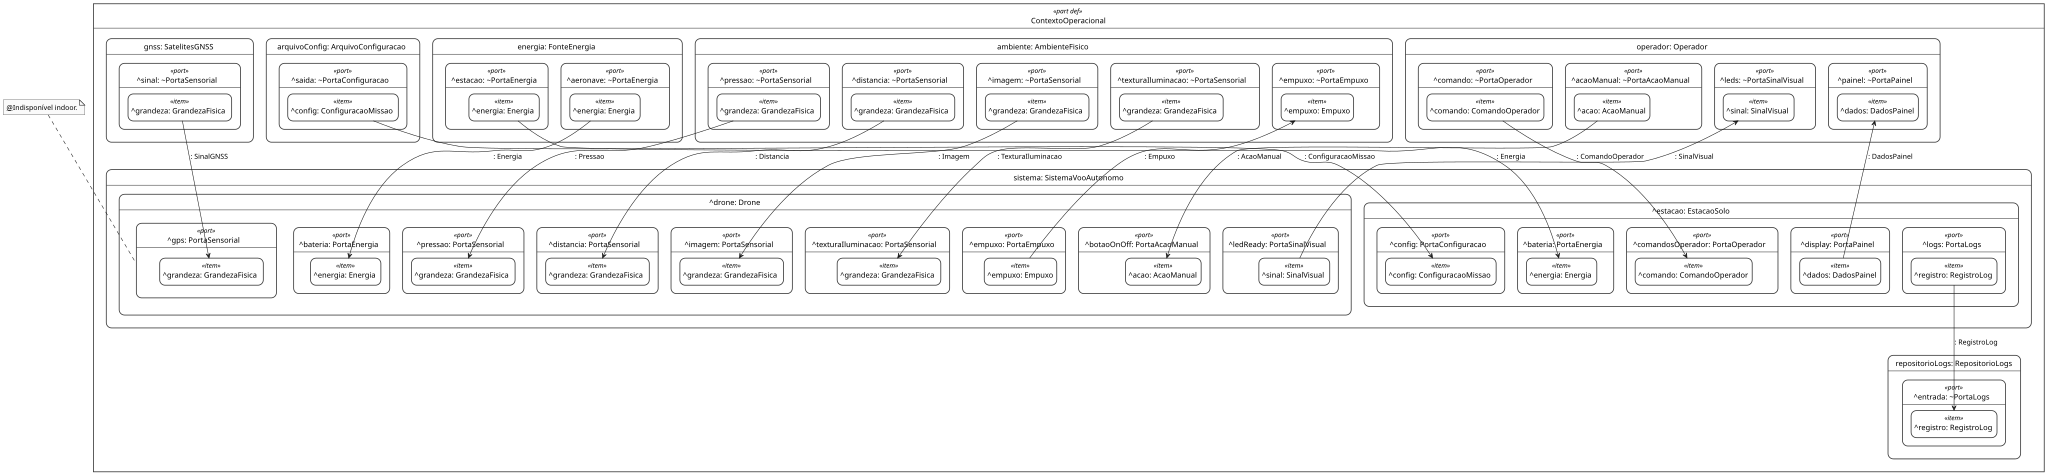

In [6]:
%viz --view=interconnection Nivel0::ContextoOperacional

### Nível 0 — cenário de operação

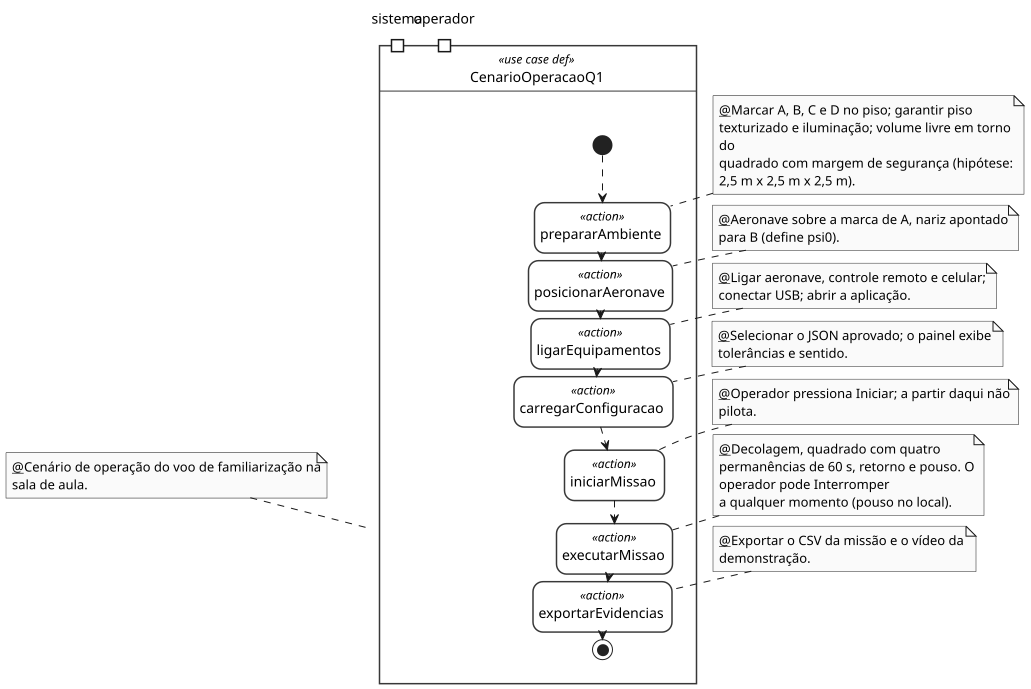

In [7]:
%viz --view=action Nivel0::CenarioOperacaoQ1

### Requisitos da Questão 1

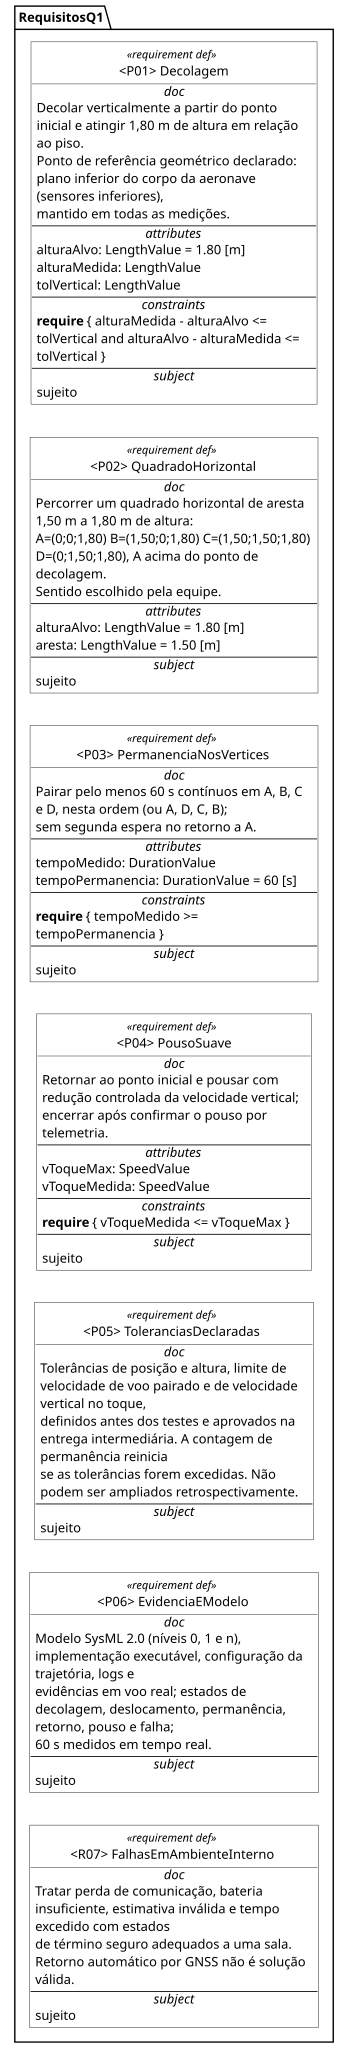

In [8]:
%viz --view=tree --style=LR Comum::RequisitosQ1

### Nível 1 — blocos do drone (caixas-pretas)

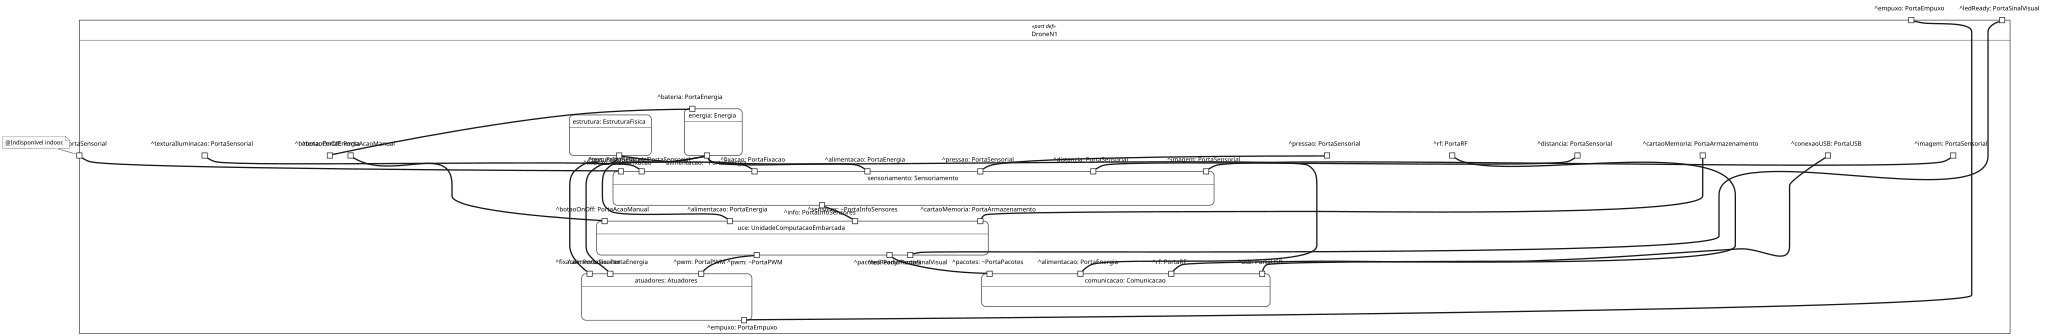

In [9]:
%viz --view=interconnection Nivel1::DroneN1

### Nível 1 — aplicação de missão

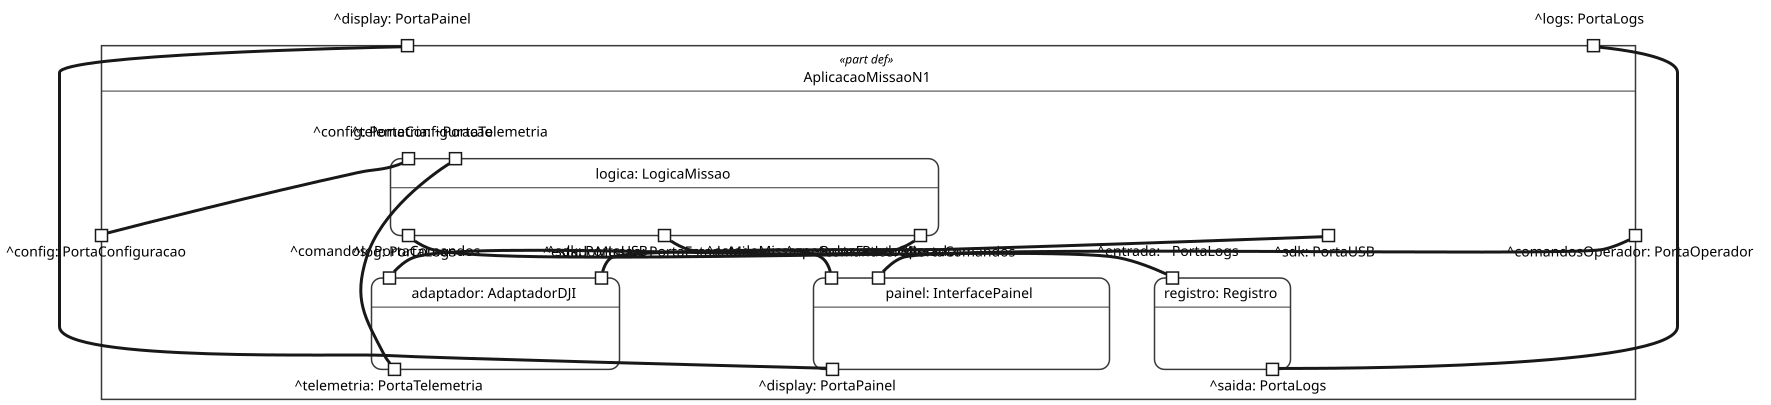

In [10]:
%viz --view=interconnection Nivel1::AplicacaoMissaoN1

### Nível 1 — decomposição funcional da função global

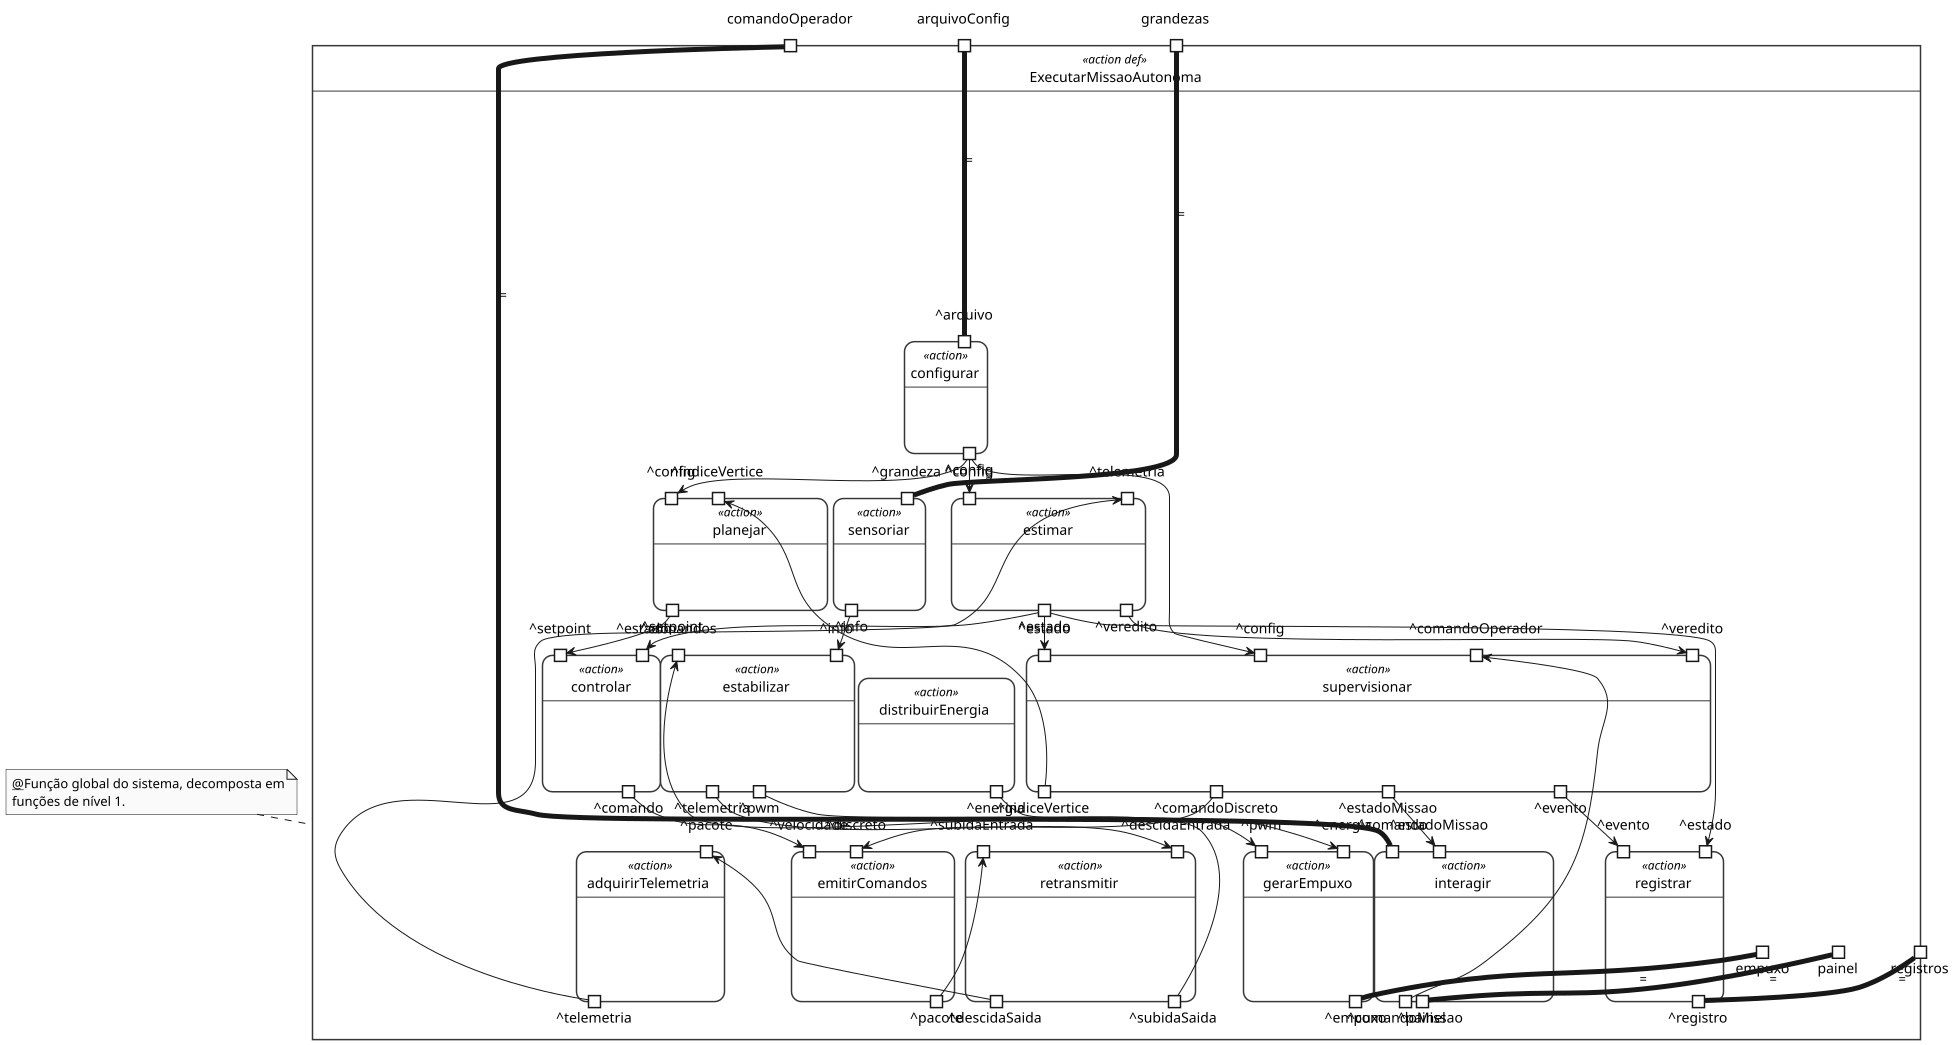

In [11]:
%viz --view=action Nivel1::ExecutarMissaoAutonoma

### Nível 1 — modos de operação

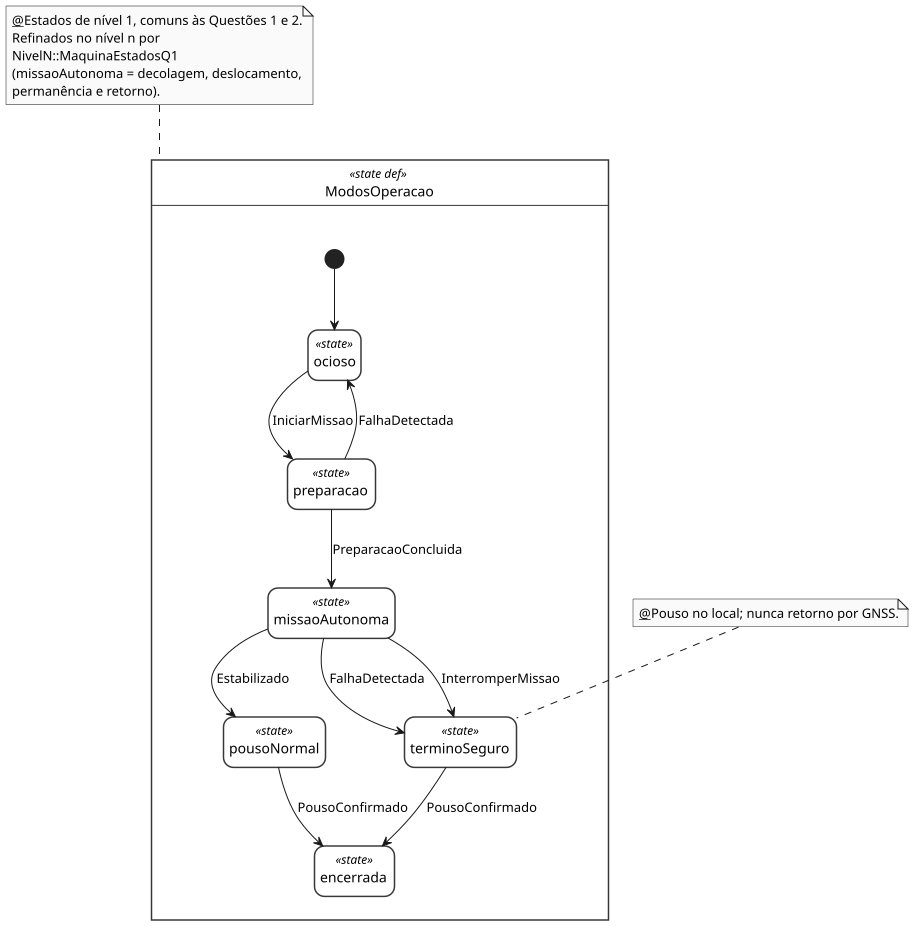

In [12]:
%viz --view=state Nivel1::ModosOperacao

### Nível n — interfaces do SDK exploradas em cada caixa-preta

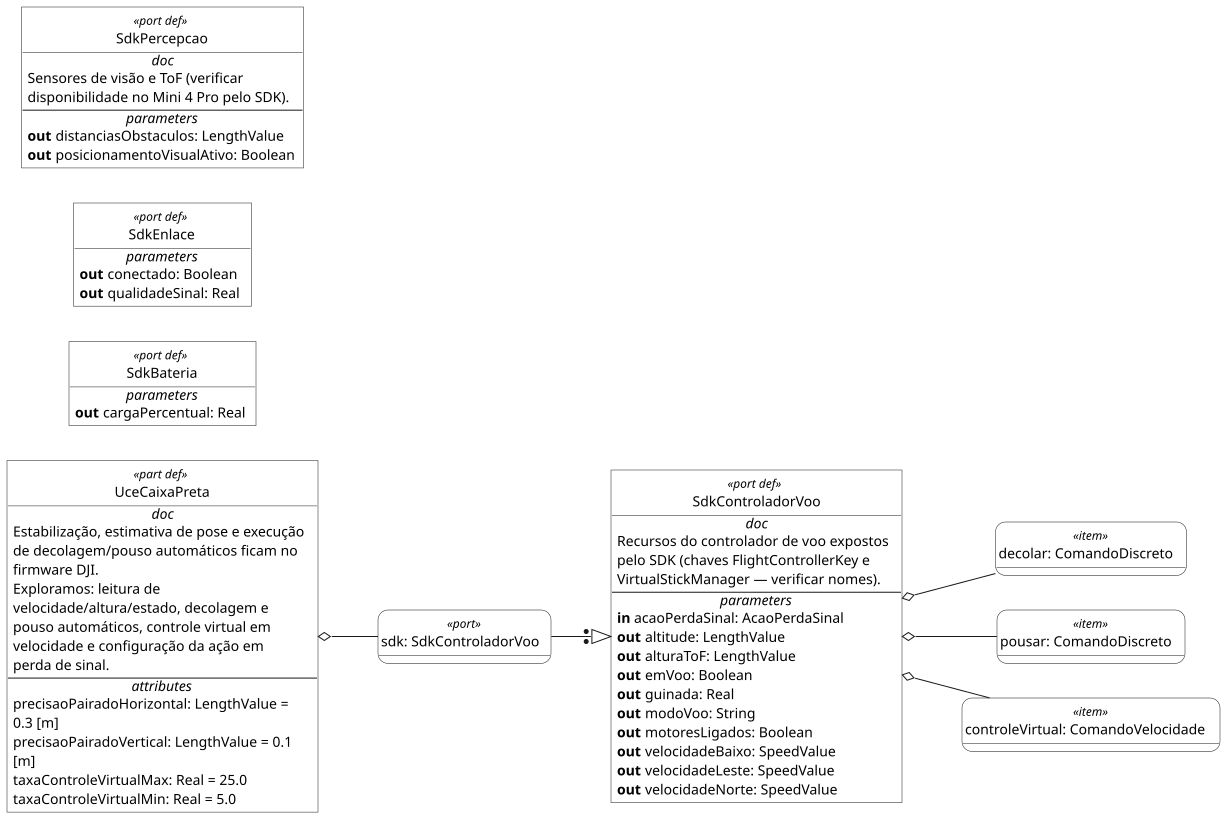

In [13]:
%viz --view=tree --style=LR NivelN::UceCaixaPreta NivelN::SdkControladorVoo NivelN::SdkBateria NivelN::SdkEnlace NivelN::SdkPercepcao

### Nível n — módulos implementáveis da aplicação

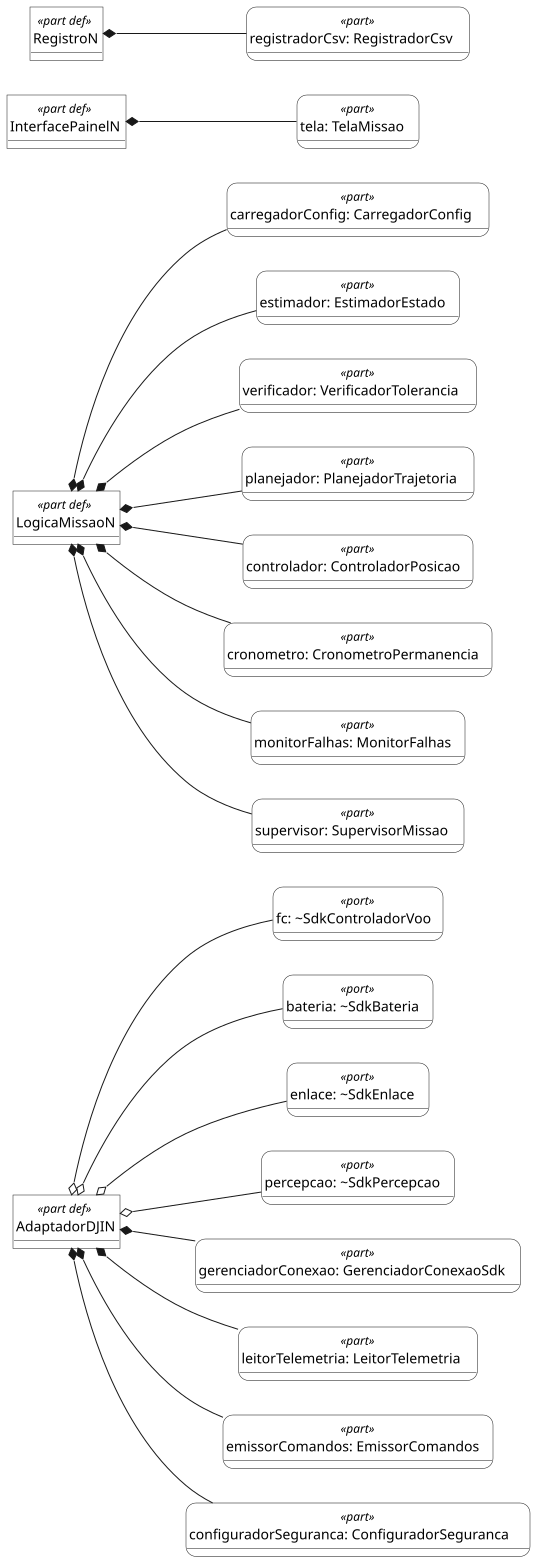

In [14]:
%viz --view=tree --style=LR NivelN::AdaptadorDJIN NivelN::LogicaMissaoN NivelN::InterfacePainelN NivelN::RegistroN

### Nível n — contratos de interface

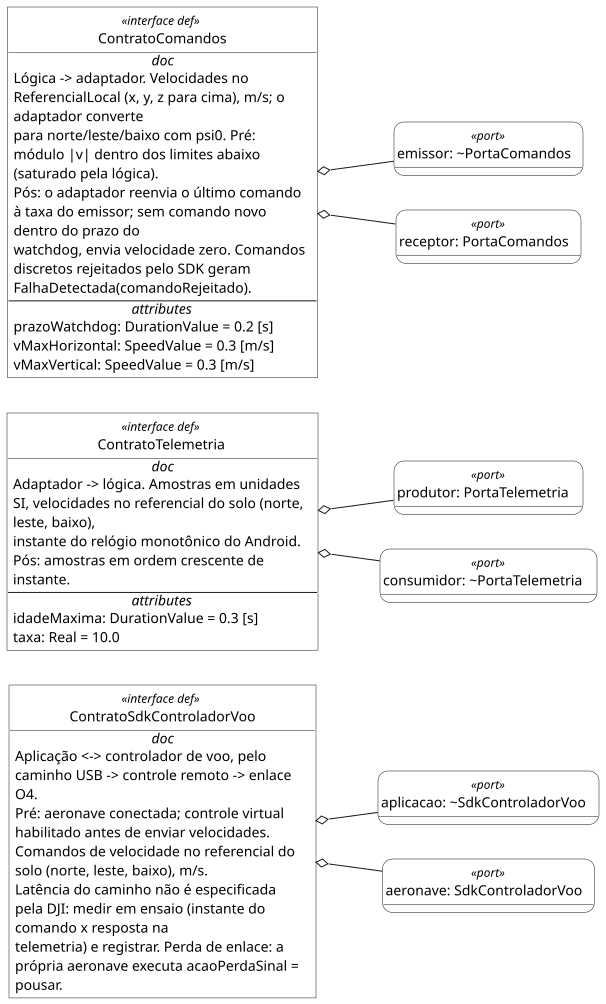

In [15]:
%viz --view=tree --style=LR NivelN::ContratoSdkControladorVoo NivelN::ContratoTelemetria NivelN::ContratoComandos

### Nível n — máquina de estados da missão (P06)

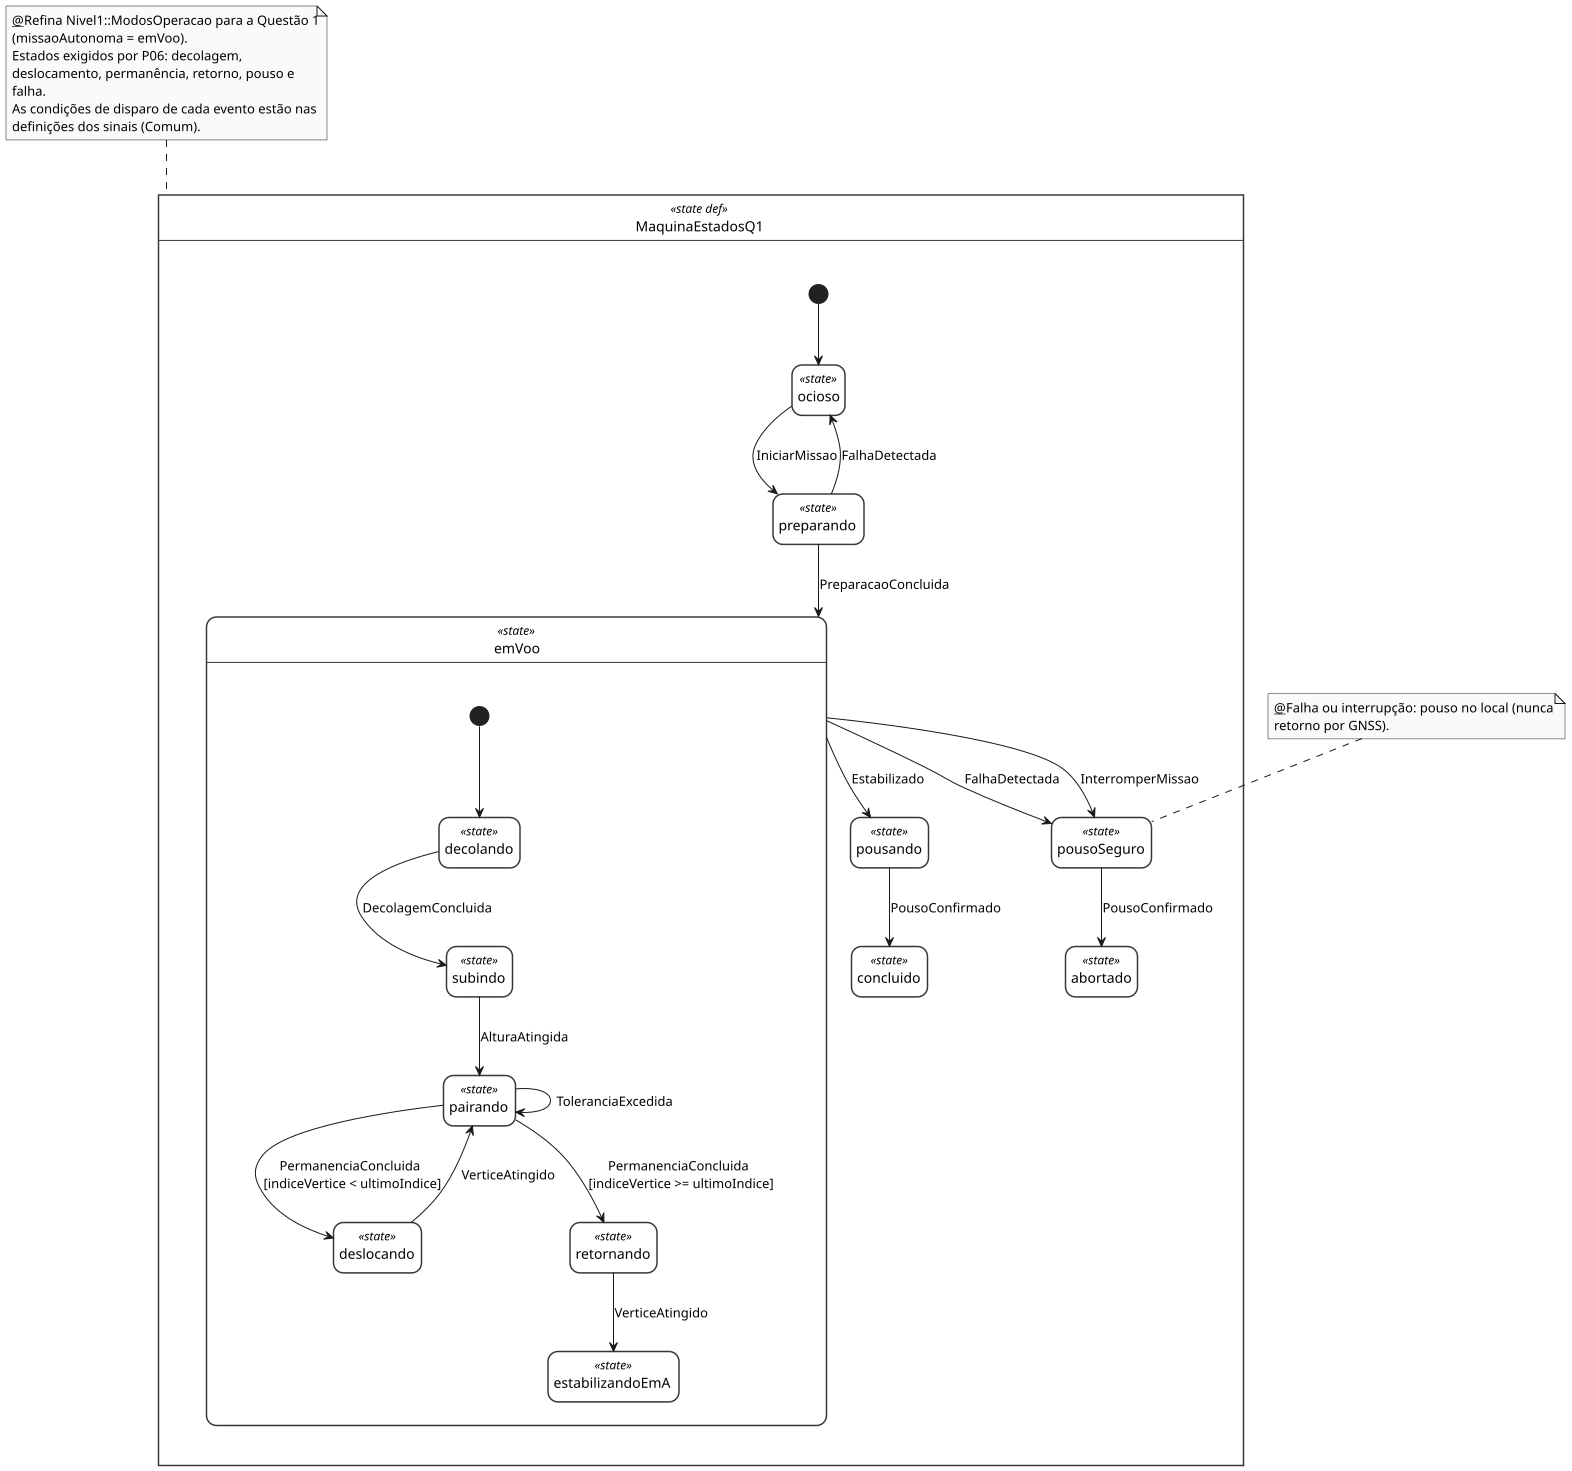

In [16]:
%viz --view=state NivelN::MaquinaEstadosQ1

### Nível n — ciclo de controle a 10 Hz

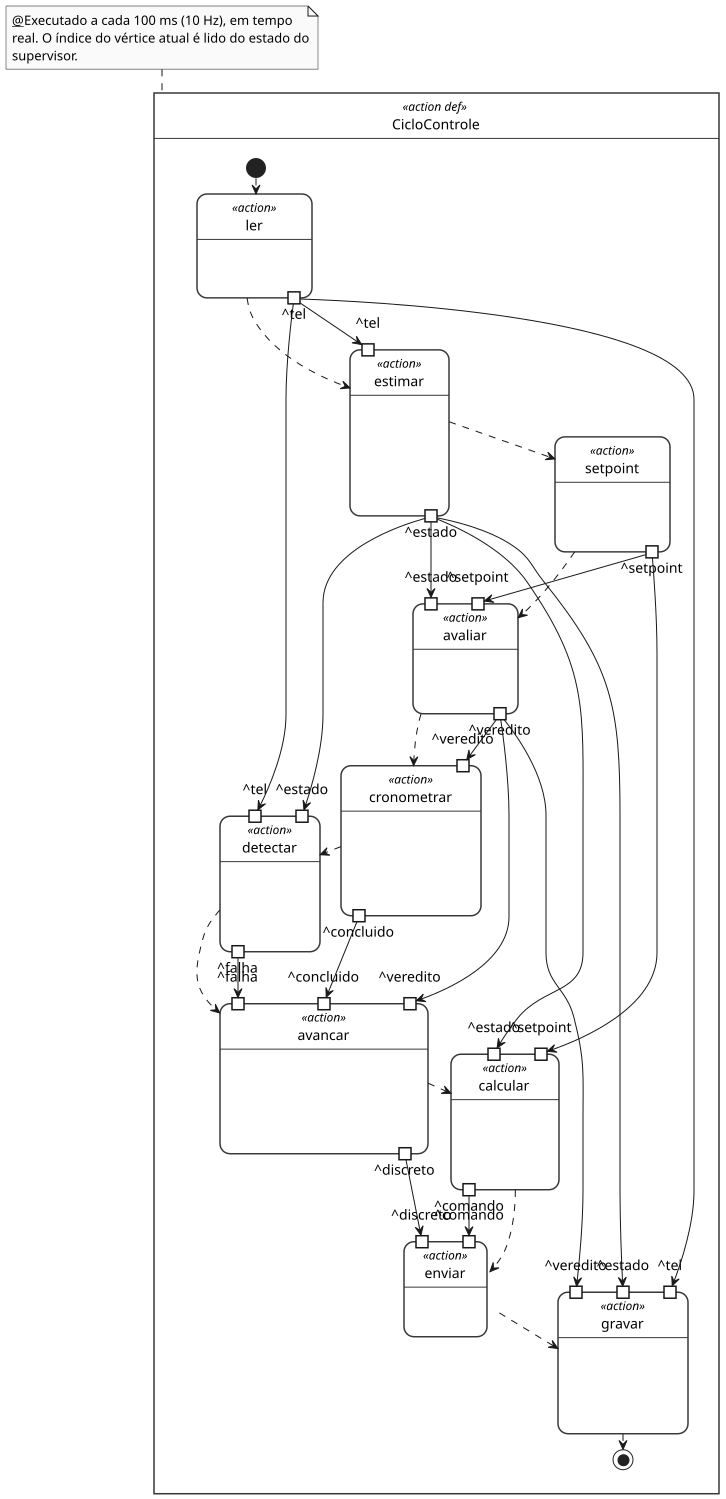

In [17]:
%viz --view=action NivelN::CicloControle

### Casos de verificação da Questão 1

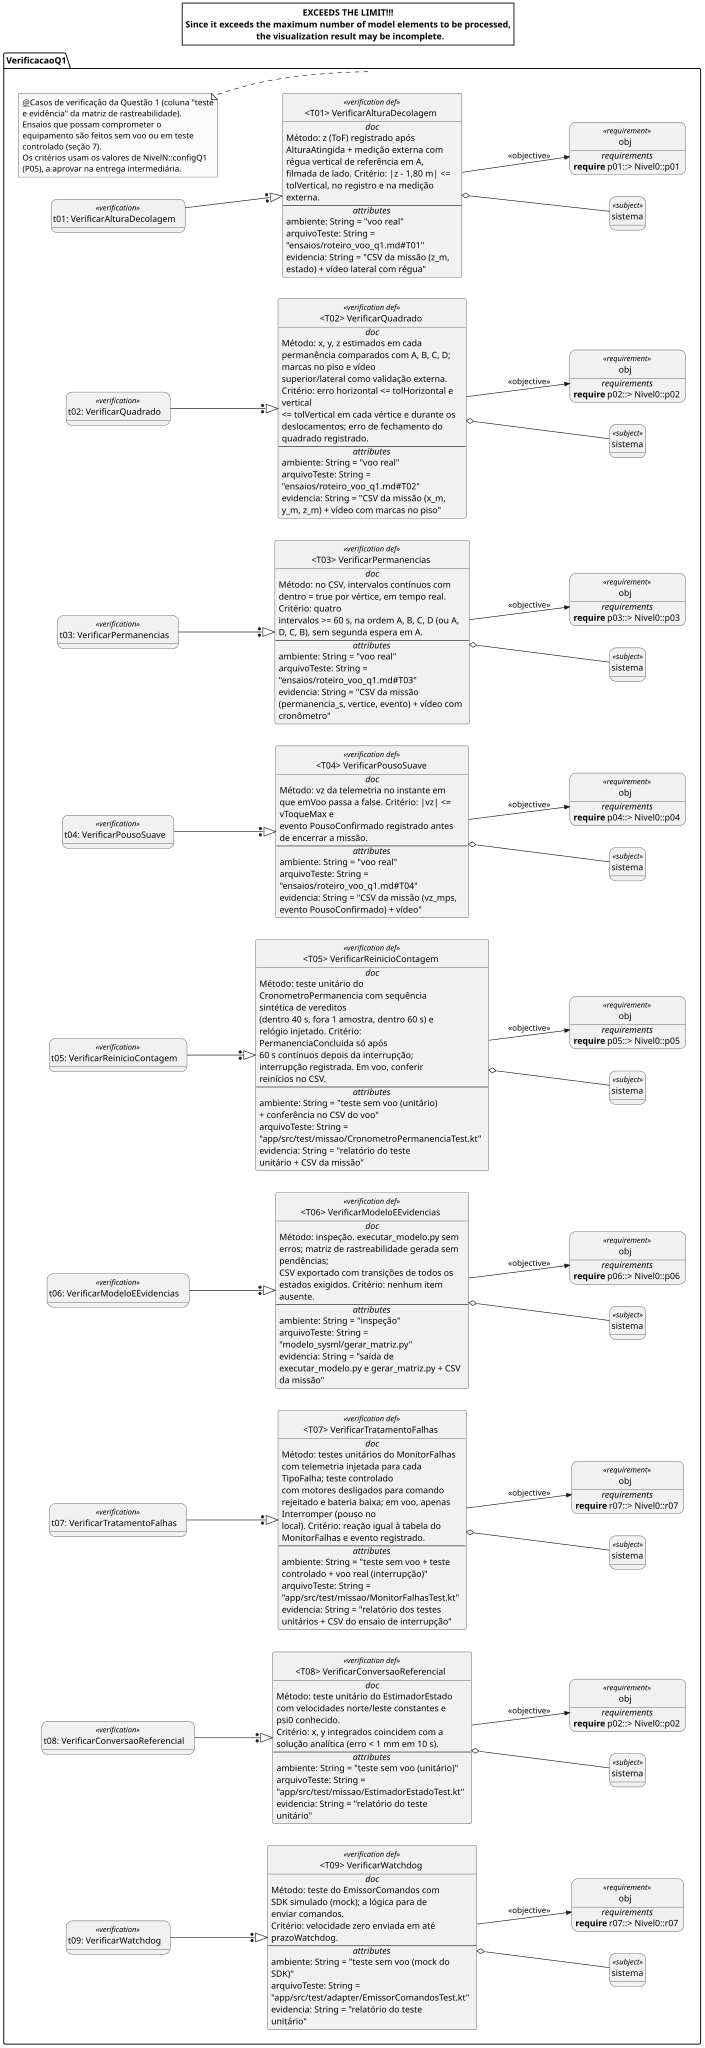

In [18]:
%viz --view=tree --style=LR VerificacaoQ1